In [ ]:
### Downloading Required Libraries
#!pip install pandas numpy matplotlib seaborn

##Import required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [9]:
###Load the dataset and list its first 5 rows, shape, info and description

df = pd.read_csv("../data/price_data.csv")

print(df.head())
print(df.shape)
df.info()
print(df.describe())

         date  avg_monthly_price
0  2005-01-01               5500
1  2005-02-01               5476
2  2005-03-01               5466
3  2005-04-01               5487
4  2005-05-01               5876
(249, 2)
<class 'pandas.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   date               249 non-null    str  
 1   avg_monthly_price  249 non-null    int64
dtypes: int64(1), str(1)
memory usage: 4.0 KB
       avg_monthly_price
count         249.000000
mean         7918.891566
std          2804.992684
min          3500.000000
25%          6123.000000
50%          7250.000000
75%          9783.000000
max         16163.000000


###Data Cleaning and Preprocessing

In [10]:
##Converting date into datetime

df['date'] = pd.to_datetime(df['date'])

print(df.info())
print(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   date               249 non-null    datetime64[us]
 1   avg_monthly_price  249 non-null    int64         
dtypes: datetime64[us](1), int64(1)
memory usage: 4.0 KB
None
        date  avg_monthly_price
0 2005-01-01               5500
1 2005-02-01               5476
2 2005-03-01               5466
3 2005-04-01               5487
4 2005-05-01               5876


In [11]:
###Checking Missing Values
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

print("\nDuplicate dates:")
print(df['date'].duplicated().sum())

Missing values:
date                 0
avg_monthly_price    0
dtype: int64

Duplicate records:
0

Duplicate dates:
0


In [12]:
###Checking chronological order and missing months

# Sort data chronologically
df = df.sort_values('date').reset_index(drop=True)

# Check date range
print("Start date:", df['date'].min())
print("End date:", df['date'].max())

# Check monthly frequency
expected_dates = pd.date_range(
    start=df['date'].min(),
    end=df['date'].max(),
    freq='MS'
)

missing_months = expected_dates.difference(df['date'])

print("Expected monthly records:", len(expected_dates))
print("Actual records:", len(df))
print("Missing months:", len(missing_months))

print(missing_months)

Start date: 2005-01-01 00:00:00
End date: 2025-09-01 00:00:00
Expected monthly records: 249
Actual records: 249
Missing months: 0
DatetimeIndex([], dtype='datetime64[us]', freq='MS')


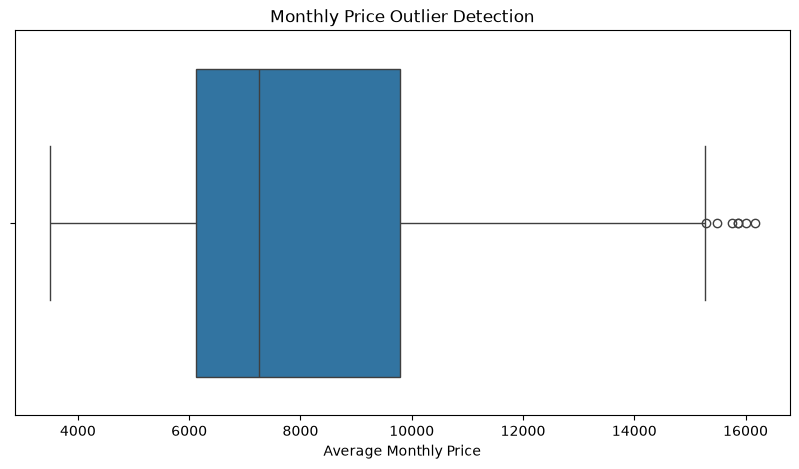

In [13]:
###Outlier detection

plt.figure(figsize=(10, 5))

sns.boxplot(x=df['avg_monthly_price'])

plt.title("Monthly Price Outlier Detection")
plt.xlabel("Average Monthly Price")

plt.show()

In [14]:
###Identify outliers using IQR

# Calculate quartiles
Q1 = df['avg_monthly_price'].quantile(0.25)
Q3 = df['avg_monthly_price'].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

# Identify outliers
outliers = df[
    (df['avg_monthly_price'] < lower_bound) |
    (df['avg_monthly_price'] > upper_bound)
]

print("\nOutlier Records:")
print(outliers)

Q1: 6123.0
Q3: 9783.0
IQR: 3660.0
Lower Bound: 633.0
Upper Bound: 15273.0

Outlier Records:
          date  avg_monthly_price
227 2023-12-01              16163
231 2024-04-01              15863
232 2024-05-01              15863
233 2024-06-01              15488
234 2024-07-01              15294
246 2025-07-01              16000
248 2025-09-01              15750


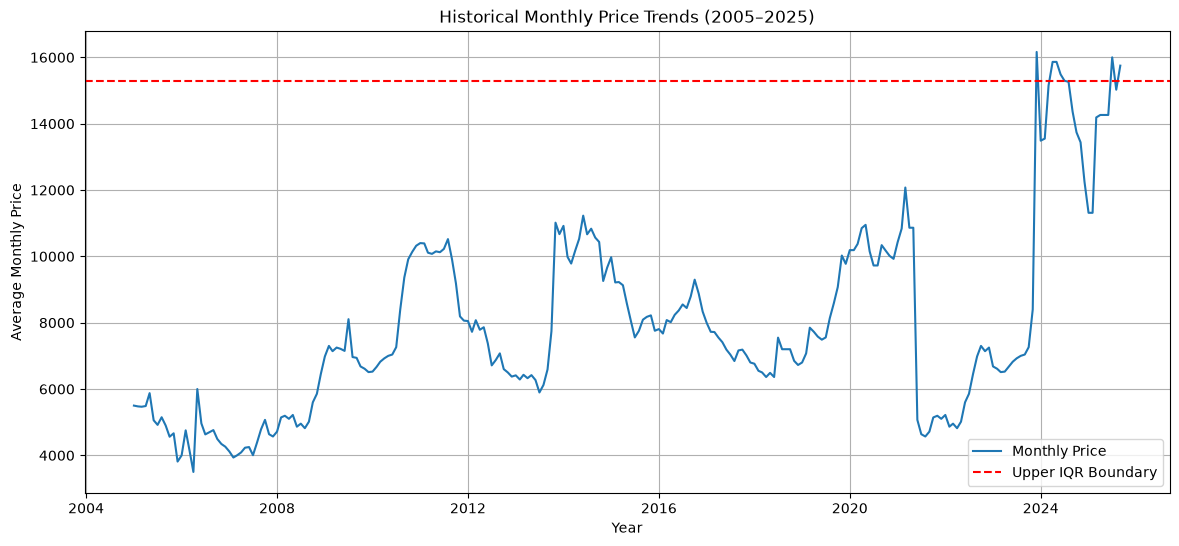

In [15]:
### Visualizing price trends

plt.figure(figsize=(14, 6))

plt.plot(
    df['date'],
    df['avg_monthly_price'],
    label='Monthly Price'
)

plt.axhline(
    upper_bound,
    color='red',
    linestyle='--',
    label='Upper IQR Boundary'
)

plt.title('Historical Monthly Price Trends (2005–2025)')
plt.xlabel('Year')
plt.ylabel('Average Monthly Price')

plt.legend()
plt.grid(True)
plt.show()

In [16]:
###Chcecking Montly continuity

expected_dates = pd.date_range(
    start=df['date'].min(),
    end=df['date'].max(),
    freq='MS'
)

missing_months = expected_dates.difference(df['date'])

print("Expected months:", len(expected_dates))
print("Actual months:", len(df))
print("Missing months:", len(missing_months))
print(missing_months)

Expected months: 249
Actual months: 249
Missing months: 0
DatetimeIndex([], dtype='datetime64[us]', freq='MS')


### Exploratory Data Analysis (EDA)

In [17]:
### Separateing date into year and month
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month

print(df.head(10))

        date  avg_monthly_price  year  month
0 2005-01-01               5500  2005      1
1 2005-02-01               5476  2005      2
2 2005-03-01               5466  2005      3
3 2005-04-01               5487  2005      4
4 2005-05-01               5876  2005      5
5 2005-06-01               5058  2005      6
6 2005-07-01               4919  2005      7
7 2005-08-01               5149  2005      8
8 2005-09-01               4899  2005      9
9 2005-10-01               4562  2005     10


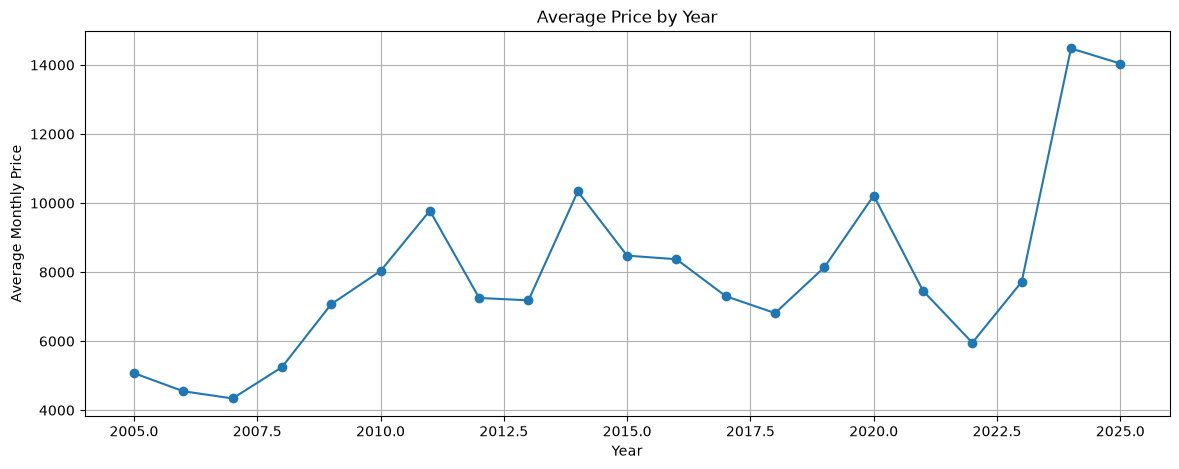

year
2005     5072.500000
2006     4548.750000
2007     4339.916667
2008     5244.500000
2009     7070.666667
2010     8031.250000
2011     9778.833333
2012     7251.000000
2013     7181.916667
2014    10335.916667
2015     8477.000000
2016     8372.833333
2017     7302.666667
2018     6812.416667
2019     8139.666667
2020    10216.833333
2021     7458.000000
2022     5954.333333
2023     7717.500000
2024    14479.000000
2025    14042.000000
Name: avg_monthly_price, dtype: float64


In [18]:
### Analyzing yearly average prices

yearly_avg = df.groupby('year')['avg_monthly_price'].mean()

plt.figure(figsize=(14, 5))

yearly_avg.plot(marker='o')

plt.title('Average Price by Year')
plt.xlabel('Year')
plt.ylabel('Average Monthly Price')

plt.grid(True)
plt.show()

print(yearly_avg)

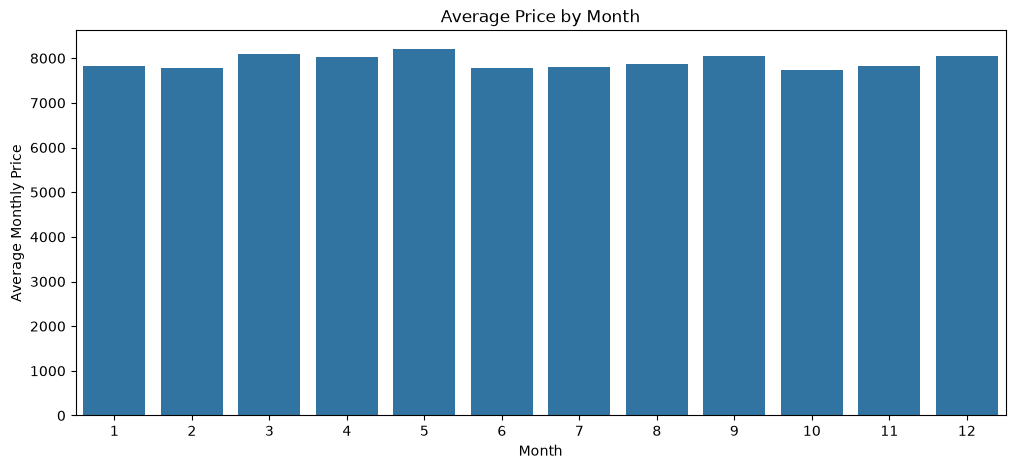

month
1     7822.476190
2     7774.666667
3     8086.857143
4     8032.428571
5     8210.238095
6     7770.190476
7     7812.666667
8     7865.523810
9     8044.380952
10    7741.950000
11    7819.250000
12    8038.600000
Name: avg_monthly_price, dtype: float64


In [19]:
### Analyzing monthly seasonality
monthly_avg = df.groupby('month')['avg_monthly_price'].mean()

plt.figure(figsize=(12, 5))

sns.barplot(
    x=monthly_avg.index,
    y=monthly_avg.values
)

plt.title('Average Price by Month')
plt.xlabel('Month')
plt.ylabel('Average Monthly Price')

plt.show()

print(monthly_avg)

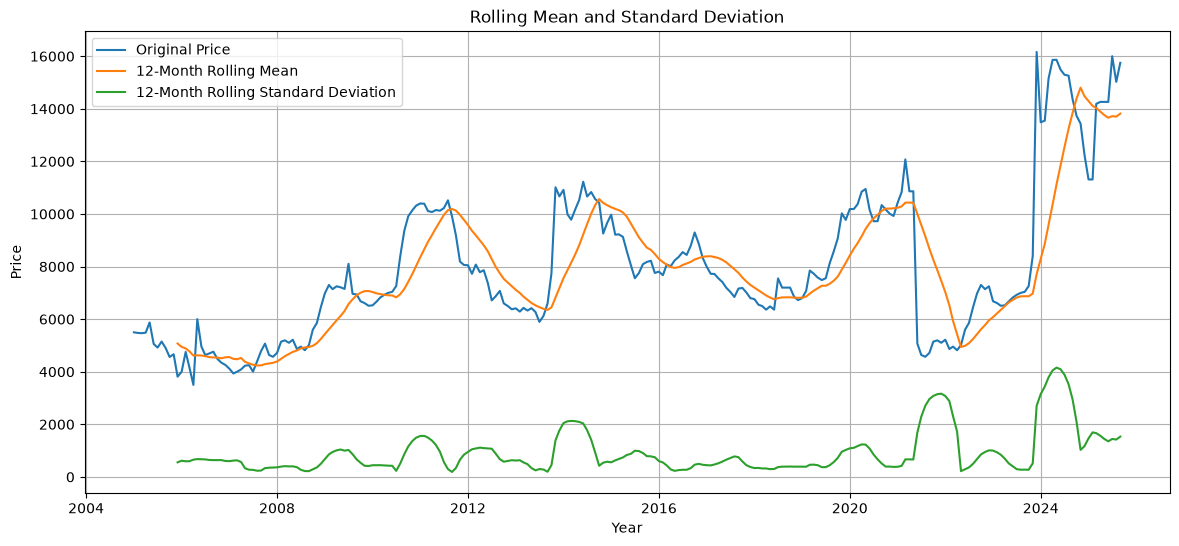

In [21]:
###Rolling mean and standard deviation
# Set date as index
df = df.set_index('date')

# Calculate rolling statistics
df['rolling_mean'] = (
    df['avg_monthly_price'].rolling(window=12).mean()
)

df['rolling_std'] = (
    df['avg_monthly_price'].rolling(window=12).std()
)

# Visualize
plt.figure(figsize=(14, 6))

plt.plot(
    df['avg_monthly_price'],
    label='Original Price'
)

plt.plot(
    df['rolling_mean'],
    label='12-Month Rolling Mean'
)

plt.plot(
    df['rolling_std'],
    label='12-Month Rolling Standard Deviation'
)

plt.title('Rolling Mean and Standard Deviation')
plt.xlabel('Year')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()

In [23]:
###Augmented Dickey-Fuller (ADF) test

from statsmodels.tsa.stattools import adfuller

result = adfuller(df['avg_monthly_price'])

print("ADF Statistic:", result[0])
print("P-value:", result[1])
print("Critical Values:")

for key, value in result[4].items():
    print(f"{key}: {value}")

if result[1] <= 0.05:
    print("\nConclusion: Data is stationary.")
else:
    print("\nConclusion: Data is non-stationary.")

ADF Statistic: -1.6310679104992176
P-value: 0.46693177566134436
Critical Values:
1%: -3.4569962781990573
5%: -2.8732659015936024
10%: -2.573018897632674

Conclusion: Data is non-stationary.


C:\Users\sivap\AppData\Local\Temp\ipykernel_2780\2607765311.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(df['avg_monthly_price'])


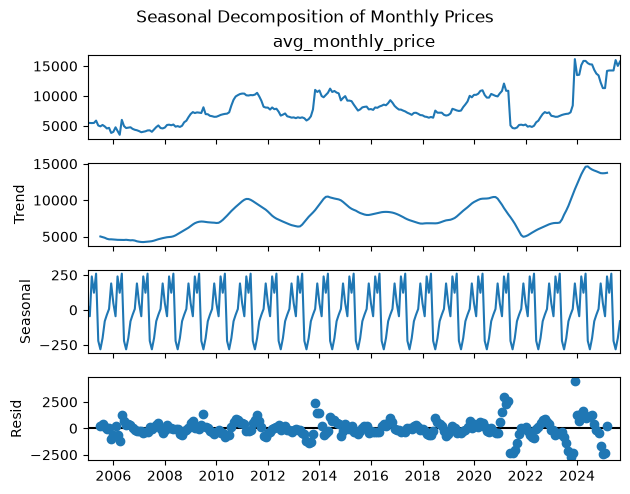

In [24]:
### Seasonal decomposition
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    df['avg_monthly_price'],
    model='additive',
    period=12
)

decomposition.plot()

plt.suptitle(
    'Seasonal Decomposition of Monthly Prices',
    y=1.02
)

plt.show()

### Making the time series stationary

In [26]:
## First-order differencing

from statsmodels.tsa.stattools import adfuller

# First-order differencing
df['price_diff'] = df['avg_monthly_price'].diff()

# Remove the first missing observation
price_diff = df['price_diff'].dropna()

# ADF test
adf_result = adfuller(price_diff)

print("ADF Statistic:", adf_result[0])
print("P-value:", adf_result[1])

if adf_result[1] <= 0.05:
    print("The differenced series is stationary.")
else:
    print("The differenced series is still non-stationary.")

ADF Statistic: -16.138421148255464
P-value: 4.70409127650809e-29
The differenced series is stationary.


C:\Users\sivap\AppData\Local\Temp\ipykernel_2780\406286093.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(price_diff)


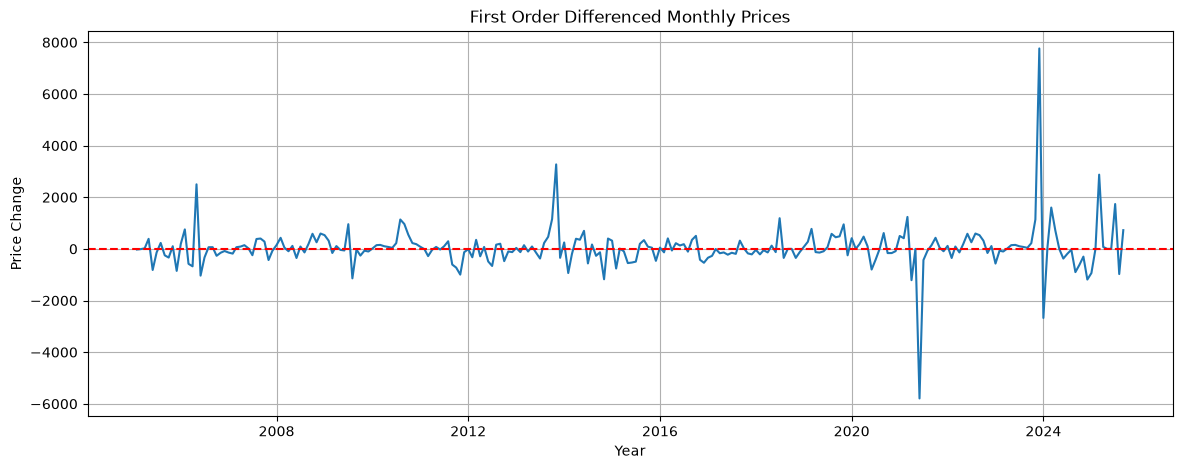

In [27]:
### Visualize differenced prices
plt.figure(figsize=(14, 5))

plt.plot(price_diff)

plt.title('First Order Differenced Monthly Prices')
plt.xlabel('Year')
plt.ylabel('Price Change')

plt.axhline(0, color='red', linestyle='--')

plt.grid(True)
plt.show()

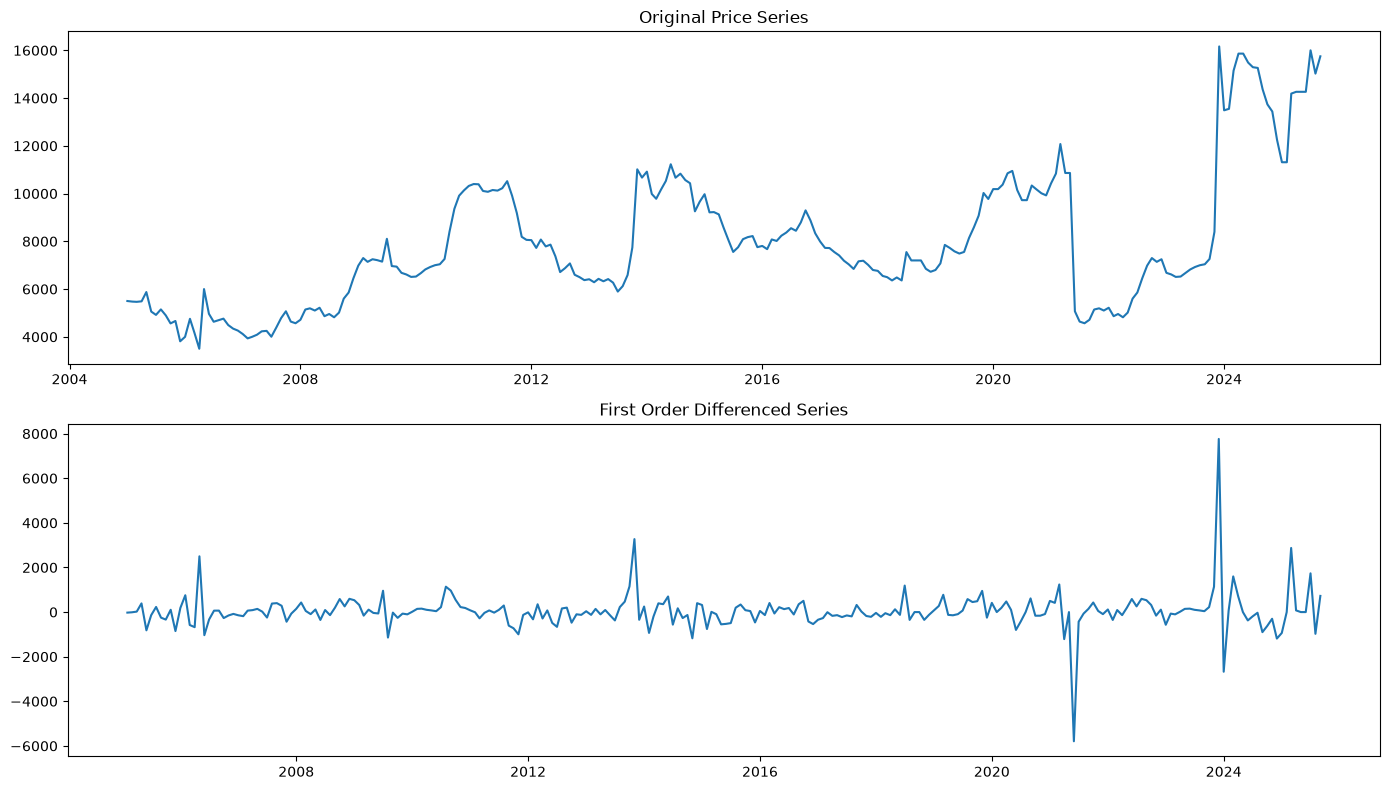

In [28]:
###Compare original and differenced series

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(df['avg_monthly_price'])
axes[0].set_title('Original Price Series')

axes[1].plot(price_diff)
axes[1].set_title('First Order Differenced Series')

plt.tight_layout()
plt.show()

## The Augmented Dickey-Fuller test was performed to examine the stationarity of the monthly price series. The original series produced a p-value of 0.4669, indicating insufficient evidence to reject the unit-root null hypothesis. First-order differencing was then applied. The differenced series produced an ADF statistic of -16.138 and a p-value of 4.70 × 10⁻²⁹. Therefore, first-order differencing was sufficient to reject the unit-root null hypothesis, and the differencing parameter d=1 was selected for further SARIMA investigation.

## Identify SARIMA parameters


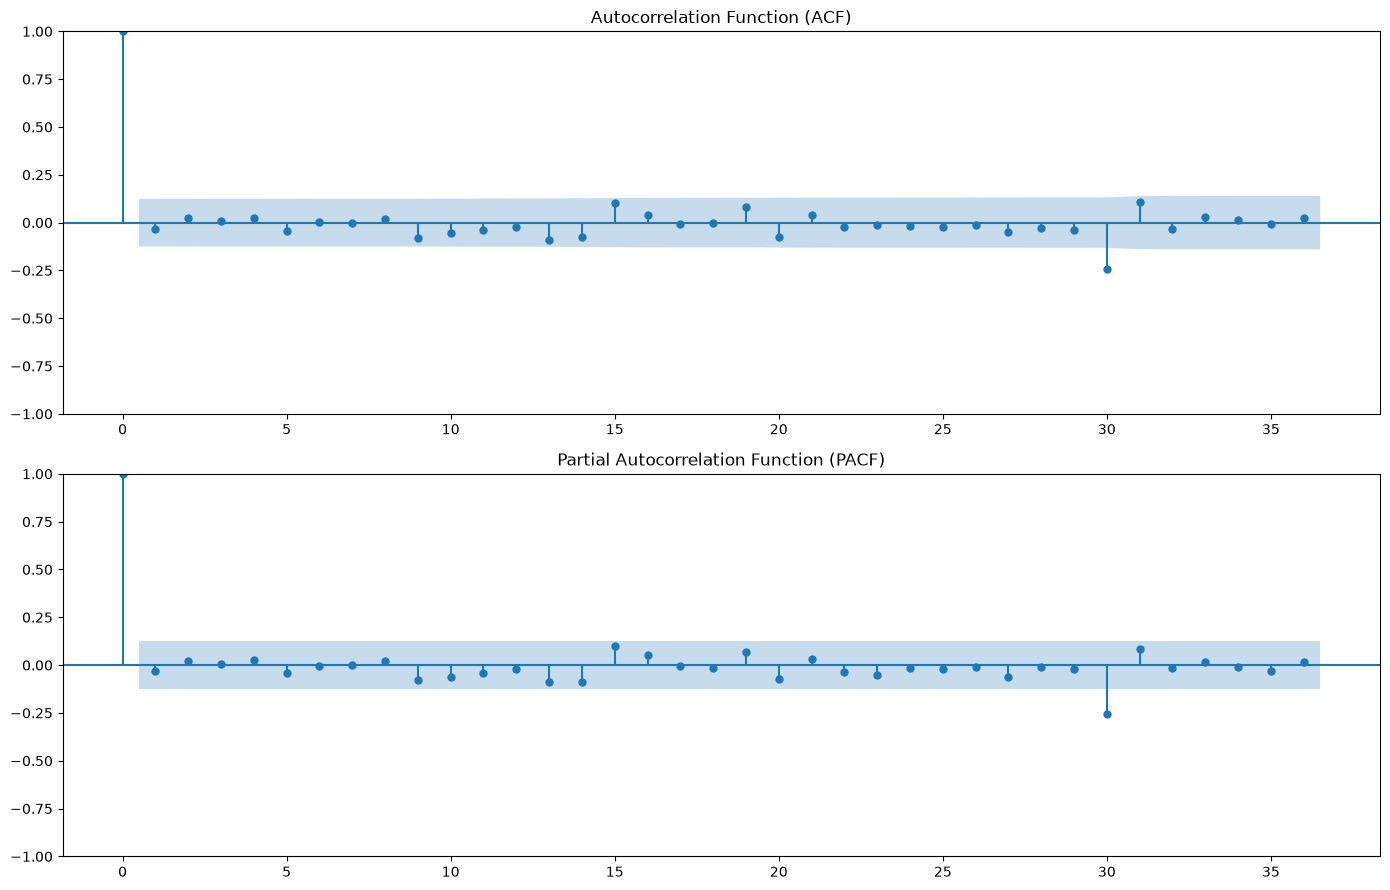

In [31]:
###ACF and PACF plots
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

plot_acf(
    price_diff,
    lags=36,
    ax=axes[0]
)

axes[0].set_title("Autocorrelation Function (ACF)")

plot_pacf(
    price_diff,
    lags=36,
    ax=axes[1],
    method='ywm'
)

axes[1].set_title("Partial Autocorrelation Function (PACF)")

plt.tight_layout()
plt.show()

In [32]:
##Investigate seasonal differencing

# Apply seasonal differencing to the first-differenced series
seasonal_diff = price_diff.diff(12).dropna()

result = adfuller(seasonal_diff)

print("Seasonally differenced ADF Statistic:", result[0])
print("Seasonally differenced P-value:", result[1])

if result[1] <= 0.05:
    print("Combined differenced series passes the ADF test.")
else:
    print("Combined differenced series remains non-stationary.")

Seasonally differenced ADF Statistic: -8.605703117656029
Seasonally differenced P-value: 6.681761527812288e-14
Combined differenced series passes the ADF test.


C:\Users\sivap\AppData\Local\Temp\ipykernel_2780\1870302801.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(seasonal_diff)


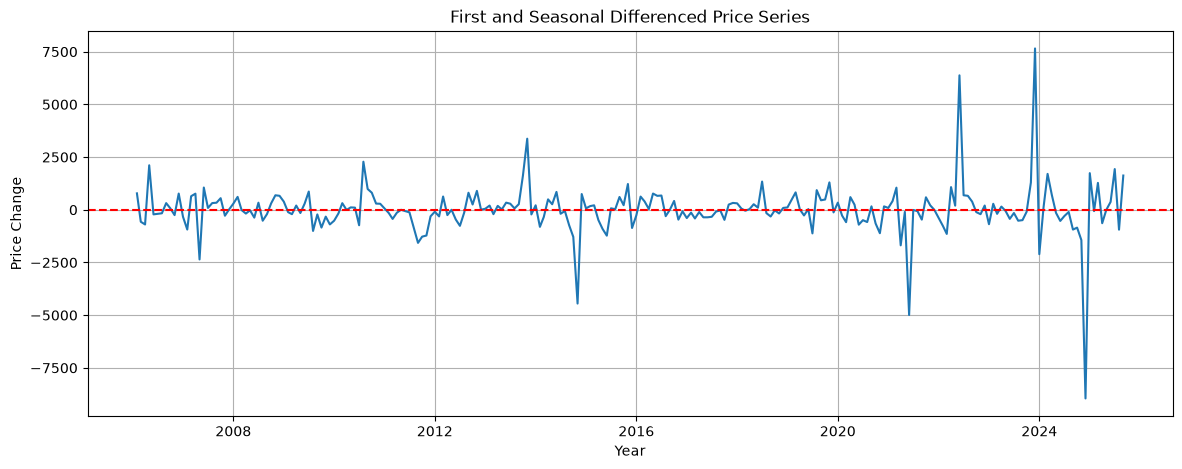

In [33]:
### Visualize seasonal differencing

plt.figure(figsize=(14, 5))

plt.plot(seasonal_diff)

plt.axhline(0, color='red', linestyle='--')

plt.title("First and Seasonal Differenced Price Series")
plt.xlabel("Year")
plt.ylabel("Price Change")

plt.grid(True)
plt.show()

### Model development

In [34]:
### Implement the three-way split

# Original time series
ts = df['avg_monthly_price'].asfreq('MS')

# Calculate split sizes
n = len(ts)

train_size = int(n * 0.70)
val_size = int(n * 0.15)

# Chronological splitting
train = ts.iloc[:train_size]

validation = ts.iloc[
    train_size:train_size + val_size
]

test = ts.iloc[
    train_size + val_size:
]

# Display dataset information
print("Total observations:", len(ts))

print("\nTraining Dataset")
print("Records:", len(train))
print("Start:", train.index.min())
print("End:", train.index.max())

print("\nValidation Dataset")
print("Records:", len(validation))
print("Start:", validation.index.min())
print("End:", validation.index.max())

print("\nTesting Dataset")
print("Records:", len(test))
print("Start:", test.index.min())
print("End:", test.index.max())

Total observations: 249

Training Dataset
Records: 174
Start: 2005-01-01 00:00:00
End: 2019-06-01 00:00:00

Validation Dataset
Records: 37
Start: 2019-07-01 00:00:00
End: 2022-07-01 00:00:00

Testing Dataset
Records: 38
Start: 2022-08-01 00:00:00
End: 2025-09-01 00:00:00


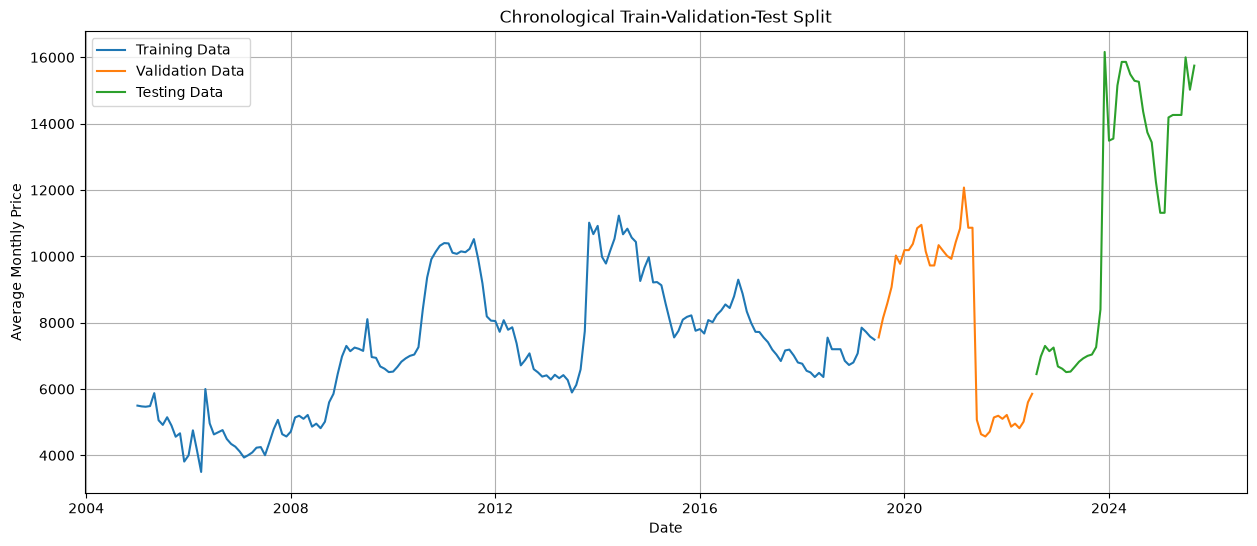

In [36]:
### Visualize the split

plt.figure(figsize=(15, 6))

plt.plot(train, label='Training Data')
plt.plot(validation, label='Validation Data')
plt.plot(test, label='Testing Data')

plt.title('Chronological Train-Validation-Test Split')
plt.xlabel('Date')
plt.ylabel('Average Monthly Price')

plt.legend()
plt.grid(True)
plt.show()

In [37]:
### Baseline model development

# Prepare the original time series
ts = df['avg_monthly_price'].asfreq('MS')

# Training, validation and testing
train = ts.iloc[:174]
validation = ts.iloc[174:211]
test = ts.iloc[211:]

# 1. Naive Forecast
naive_predictions = pd.Series(
    train.iloc[-1],
    index=validation.index
)

# 2. Seasonal Naive Forecast
seasonal_predictions = pd.Series(
    [train.iloc[-12 + (i % 12)] for i in range(len(validation))],
    index=validation.index
)

print("Baseline predictions generated.")

Baseline predictions generated.


In [40]:
### Evaluating both models

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

def evaluate_model(actual, predicted, model_name):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    mape = np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100

    return {
        'Model': model_name,
        'MAE': round(mae, 2),
        'RMSE': round(rmse, 2),
        'MAPE (%)': round(mape, 2)
    }


results = []

results.append(
    evaluate_model(validation, naive_predictions, 'Naive')
)

results.append(
    evaluate_model(validation, seasonal_predictions, 'Seasonal Naive')
)

baseline_results = pd.DataFrame(results)

display(baseline_results)

,Model,MAE,RMSE,MAPE (%)
0,Naive,2504.59,2625.18,33.77
1,Seasonal Naive,2576.86,2708.96,33.87


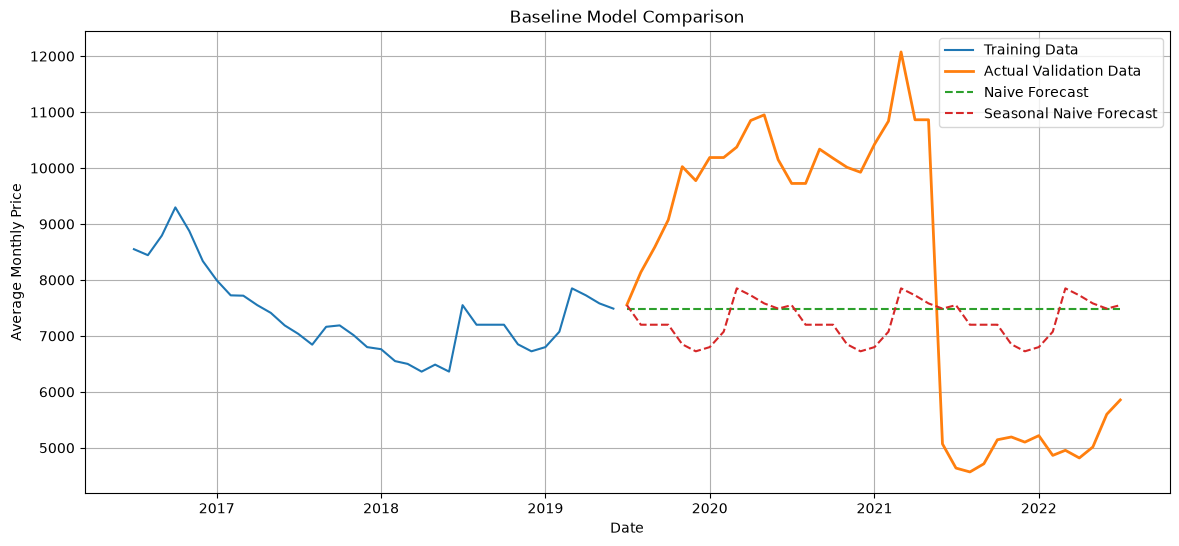

In [39]:
### Visualize the predictions
plt.figure(figsize=(14, 6))

plt.plot(
    train.iloc[-36:],
    label='Training Data'
)

plt.plot(
    validation,
    label='Actual Validation Data',
    linewidth=2
)

plt.plot(
    naive_predictions,
    label='Naive Forecast',
    linestyle='--'
)

plt.plot(
    seasonal_predictions,
    label='Seasonal Naive Forecast',
    linestyle='--'
)

plt.title('Baseline Model Comparison')
plt.xlabel('Date')
plt.ylabel('Average Monthly Price')

plt.legend()
plt.grid(True)
plt.show()

### Holt-Winters forecasting

In [42]:
### Train Holt-Winters models

from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Store predictions and results
hw_predictions = {}
hw_results = []

# Model configurations
hw_configs = {
    'HW Additive': {
        'trend': 'add',
        'seasonal': 'add',
        'damped_trend': False
    },

    'HW Damped': {
        'trend': 'add',
        'seasonal': 'add',
        'damped_trend': True
    },

    'HW Multiplicative': {
        'trend': 'add',
        'seasonal': 'mul',
        'damped_trend': True
    }
}

# Train and forecast
for name, config in hw_configs.items():

    try:
        model = ExponentialSmoothing(
            train,
            trend=config['trend'],
            seasonal=config['seasonal'],
            seasonal_periods=12,
            damped_trend=config['damped_trend'],
            initialization_method='estimated'
        )

        fitted_model = model.fit(optimized=True)

        predictions = fitted_model.forecast(
            steps=len(validation)
        )

        predictions.index = validation.index

        hw_predictions[name] = predictions

        metrics = evaluate_model(
            validation,
            predictions,
            name
        )

        hw_results.append(metrics)

        print(name, "completed successfully")

    except Exception as e:
        print(name, "failed:", e)

# Display results
hw_results_df = pd.DataFrame(hw_results)

display(hw_results_df)

HW Additive completed successfully
HW Damped completed successfully
HW Multiplicative completed successfully


,Model,MAE,RMSE,MAPE (%)
0,HW Additive,2544.19,2676.86,36.74
1,HW Damped,2490.99,2603.32,33.86
2,HW Multiplicative,2467.38,2588.45,33.87


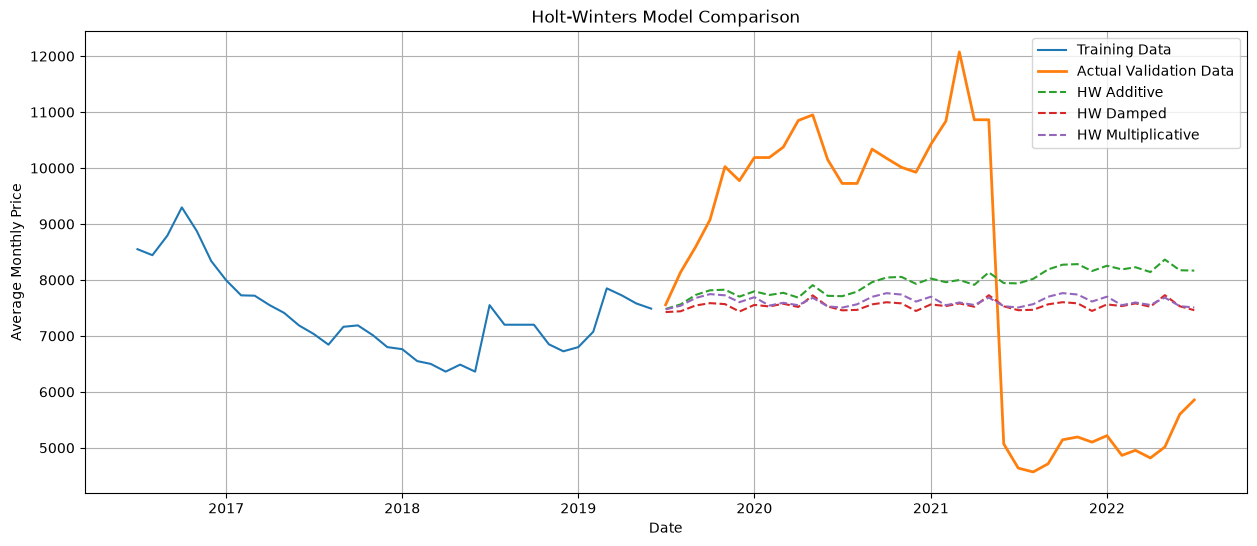

In [43]:
### Visualize Holt-Winters predictions

plt.figure(figsize=(15, 6))

plt.plot(
    train.iloc[-36:],
    label='Training Data'
)

plt.plot(
    validation,
    label='Actual Validation Data',
    linewidth=2
)

for name, predictions in hw_predictions.items():

    plt.plot(
        predictions,
        linestyle='--',
        label=name
    )

plt.title('Holt-Winters Model Comparison')

plt.xlabel('Date')
plt.ylabel('Average Monthly Price')

plt.legend()
plt.grid(True)
plt.show()

In [44]:
### Compare all baseline and Holt-Winters models
all_results = baseline_results.copy()

all_results = pd.concat(
    [all_results, hw_results_df],
    ignore_index=True
)

all_results = all_results.sort_values(
    by='RMSE'
).reset_index(drop=True)

display(all_results)

,Model,MAE,RMSE,MAPE (%)
0,HW Multiplicative,2467.38,2588.45,33.87
1,HW Damped,2490.99,2603.32,33.86
2,Naive,2504.59,2625.18,33.77
3,HW Additive,2544.19,2676.86,36.74
4,Seasonal Naive,2576.86,2708.96,33.87


### Training-only stationarity test

In [45]:
from statsmodels.tsa.stattools import adfuller

# First difference of training data only
train_diff = train.diff().dropna()

result = adfuller(train_diff)

print("Training-only ADF results")
print("-------------------------")
print("ADF Statistic:", result[0])
print("P-value:", result[1])

if result[1] < 0.05:
    print("Training differenced series is stationary.")
else:
    print("Training differenced series is non-stationary.")

Training-only ADF results
-------------------------
ADF Statistic: -12.51799869611021
P-value: 2.5857400058149166e-23
Training differenced series is stationary.


C:\Users\sivap\AppData\Local\Temp\ipykernel_2780\372133752.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(train_diff)


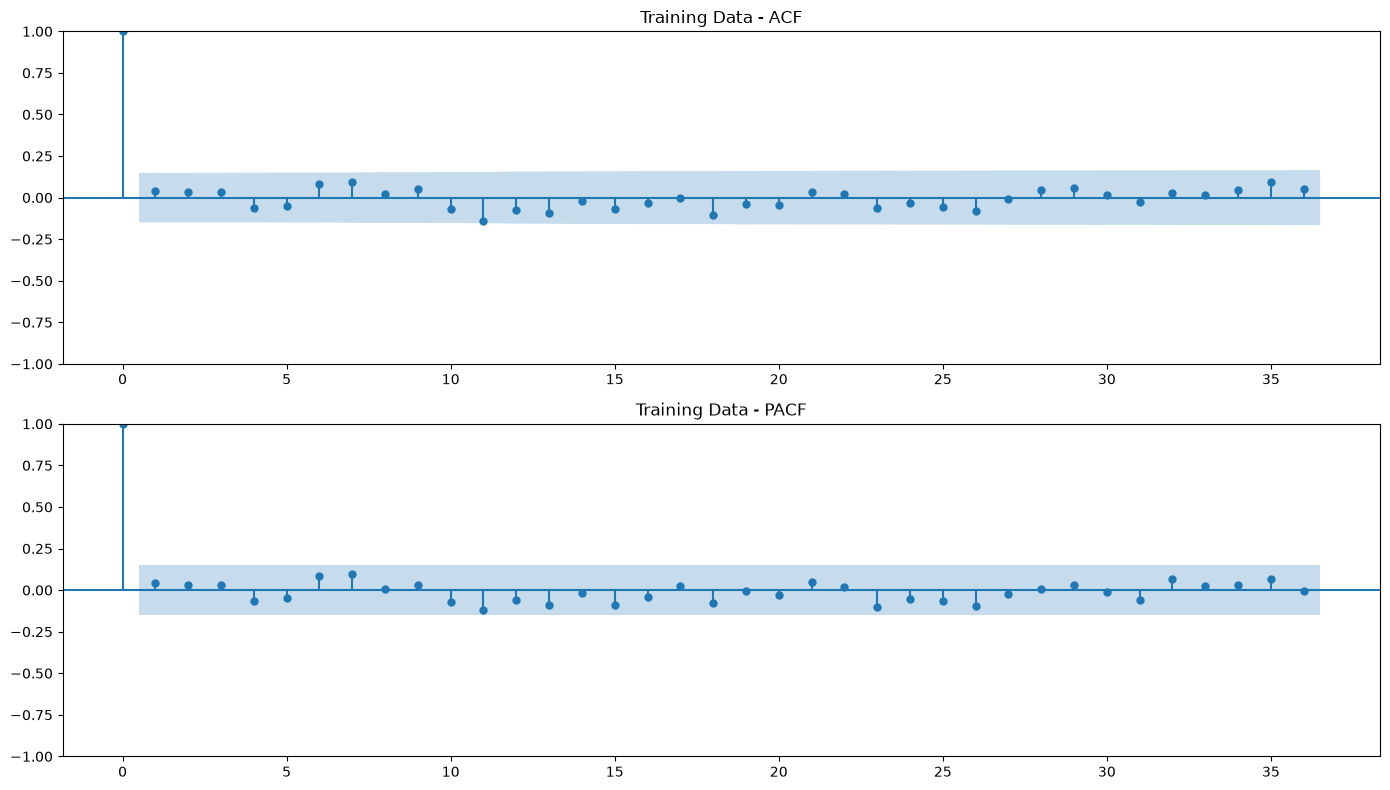

In [46]:
### Training-only ACF and PACF
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

plot_acf(train_diff, lags=36, ax=axes[0])
axes[0].set_title("Training Data - ACF")

plot_pacf(train_diff, lags=36, ax=axes[1], method='ywm')
axes[1].set_title("Training Data - PACF")

plt.tight_layout()
plt.show()

### Train SARIMA models

In [47]:
### Import SARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings

warnings.filterwarnings("ignore")

In [48]:
### Fit and evaluate SARIMA
sarima_configs = {
    'SARIMA 1': ((0, 1, 0), (0, 0, 0, 12)),
    'SARIMA 2': ((1, 1, 0), (0, 0, 0, 12)),
    'SARIMA 3': ((0, 1, 1), (0, 0, 0, 12)),
    'SARIMA 4': ((1, 1, 1), (0, 0, 0, 12)),
    'SARIMA 5': ((0, 1, 1), (0, 1, 1, 12)),
    'SARIMA 6': ((1, 1, 1), (1, 1, 1, 12))
}

sarima_predictions = {}
sarima_results = []

for name, (order, seasonal_order) in sarima_configs.items():

    try:
        model = SARIMAX(
            train,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        fitted_model = model.fit(
            disp=False,
            maxiter=300
        )

        # Forecast the entire validation period
        predictions = fitted_model.forecast(
            steps=len(validation)
        )

        predictions.index = validation.index

        sarima_predictions[name] = predictions

        metrics = evaluate_model(
            validation,
            predictions,
            name
        )

        sarima_results.append(metrics)

        print(name, "completed")
        print("AIC:", round(fitted_model.aic, 2))

    except Exception as e:
        print(name, "failed:", e)

sarima_results_df = pd.DataFrame(sarima_results)

display(
    sarima_results_df.sort_values(
        by='RMSE'
    ).reset_index(drop=True)
)

SARIMA 1 completed
AIC: 2631.63
SARIMA 2 completed
AIC: 2633.34
SARIMA 3 completed
AIC: 2619.07
SARIMA 4 completed
AIC: 2620.91
SARIMA 5 completed
AIC: 2274.79
SARIMA 6 completed
AIC: 2276.96


,Model,MAE,RMSE,MAPE (%)
0,SARIMA 1,2504.59,2625.18,33.77
1,SARIMA 3,2505.42,2626.04,33.77
2,SARIMA 2,2505.56,2626.19,33.77
3,SARIMA 6,2511.15,2626.39,34.69
4,SARIMA 4,2506.70,2627.53,33.76
5,SARIMA 5,2525.79,2648.41,35.98


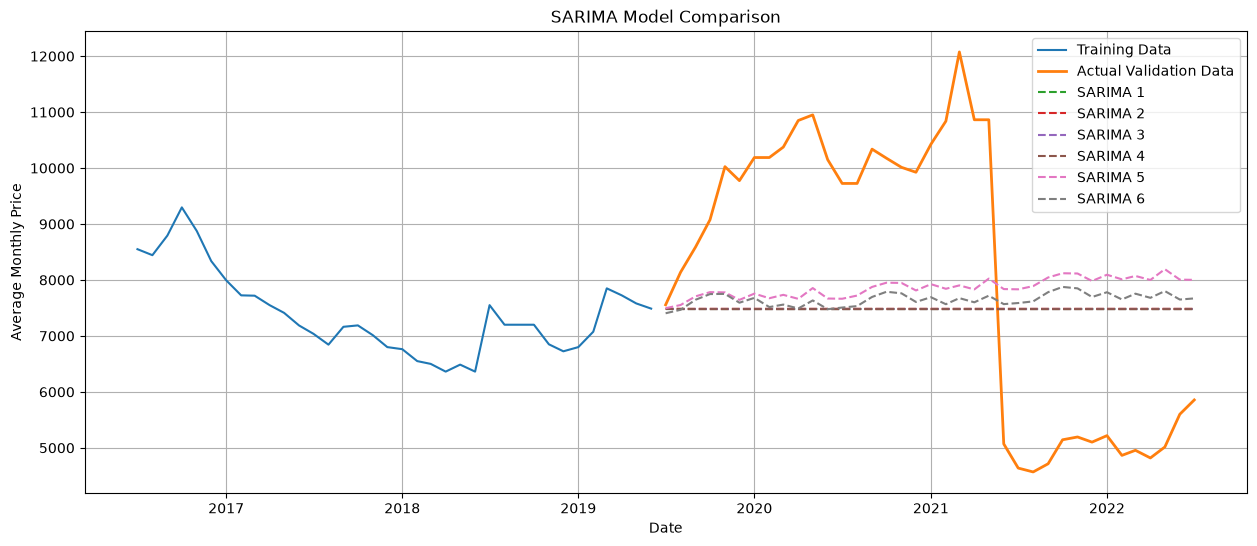

In [49]:
### Visualize SARIMA predictions

plt.figure(figsize=(15, 6))

plt.plot(
    train.iloc[-36:],
    label='Training Data'
)

plt.plot(
    validation,
    label='Actual Validation Data',
    linewidth=2
)

for name, predictions in sarima_predictions.items():

    plt.plot(
        predictions,
        linestyle='--',
        label=name
    )

plt.title('SARIMA Model Comparison')

plt.xlabel('Date')
plt.ylabel('Average Monthly Price')

plt.legend()
plt.grid(True)
plt.show()

In [50]:
### Compare all models
all_results = pd.concat(
    [
        baseline_results,
        hw_results_df,
        sarima_results_df
    ],
    ignore_index=True
)

all_results = all_results.sort_values(
    by='RMSE'
).reset_index(drop=True)

print("Complete Model Comparison")

display(all_results)

Complete Model Comparison


,Model,MAE,RMSE,MAPE (%)
0,HW Multiplicative,2467.38,2588.45,33.87
1,HW Damped,2490.99,2603.32,33.86
2,SARIMA 1,2504.59,2625.18,33.77
3,Naive,2504.59,2625.18,33.77
4,SARIMA 3,2505.42,2626.04,33.77
5,SARIMA 2,2505.56,2626.19,33.77
6,SARIMA 6,2511.15,2626.39,34.69
7,SARIMA 4,2506.70,2627.53,33.76
8,SARIMA 5,2525.79,2648.41,35.98
9,HW Additive,2544.19,2676.86,36.74


### Residual diagnostics

In [51]:
## Fit the selected candidate again

from statsmodels.tsa.holtwinters import ExponentialSmoothing

best_hw_model = ExponentialSmoothing(
    train,
    trend='add',
    seasonal='mul',
    seasonal_periods=12,
    damped_trend=True,
    initialization_method='estimated'
)

best_hw_fit = best_hw_model.fit(optimized=True)

residuals = best_hw_fit.resid

print("Residual mean:", residuals.mean())
print("Residual standard deviation:", residuals.std())

Residual mean: 11.447761879224396
Residual standard deviation: 493.7674809366607


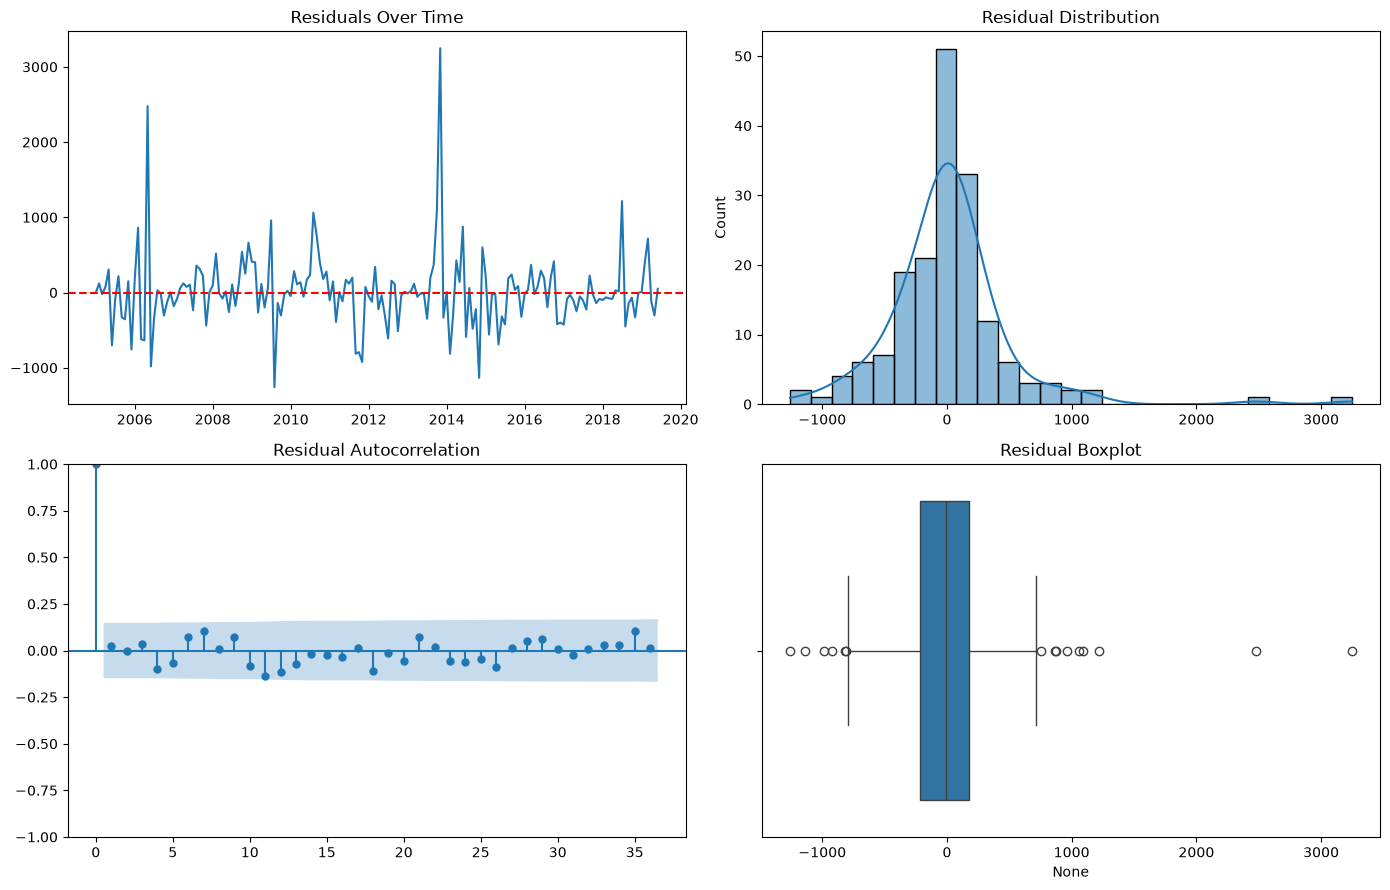

In [52]:
### Plot residuals
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Residual time series
axes[0, 0].plot(residuals)
axes[0, 0].axhline(0, color='red', linestyle='--')
axes[0, 0].set_title("Residuals Over Time")

# Residual distribution
sns.histplot(residuals, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Residual Distribution")

# Residual ACF
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(residuals.dropna(), lags=36, ax=axes[1, 0])
axes[1, 0].set_title("Residual Autocorrelation")

# Residual boxplot
sns.boxplot(x=residuals, ax=axes[1, 1])
axes[1, 1].set_title("Residual Boxplot")

plt.tight_layout()
plt.show()

In [53]:
### Ljung-Box test

from statsmodels.stats.diagnostic import acorr_ljungbox

ljung_box = acorr_ljungbox(
    residuals.dropna(),
    lags=[12, 24],
    return_df=True
)

display(ljung_box)

,lb_stat,lb_pvalue
12,13.972553,0.302464
24,20.911018,0.643969


### Rolling-origin validation

In [54]:
###Implement rolling-origin validation

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Use only training + validation data
development_data = ts.iloc[:210]

fold_origins = [174, 186, 198]

rolling_results = []

for fold, origin in enumerate(fold_origins, start=1):

    fold_train = development_data.iloc[:origin]
    fold_actual = development_data.iloc[origin:origin + 12]

    predictions = {}

    # 1. Naive
    predictions['Naive'] = pd.Series(
        fold_train.iloc[-1],
        index=fold_actual.index
    )

    # 2. Seasonal Naive
    predictions['Seasonal Naive'] = pd.Series(
        [fold_train.iloc[-12 + (i % 12)] for i in range(12)],
        index=fold_actual.index
    )

    # 3. Holt-Winters Multiplicative
    hw_model = ExponentialSmoothing(
        fold_train,
        trend='add',
        seasonal='mul',
        seasonal_periods=12,
        damped_trend=True,
        initialization_method='estimated'
    )

    hw_fit = hw_model.fit(optimized=True)

    predictions['HW Multiplicative'] = hw_fit.forecast(12)

    # 4. Holt-Winters Damped
    hw_damped = ExponentialSmoothing(
        fold_train,
        trend='add',
        seasonal='add',
        seasonal_periods=12,
        damped_trend=True,
        initialization_method='estimated'
    )

    hw_damped_fit = hw_damped.fit(optimized=True)

    predictions['HW Damped'] = hw_damped_fit.forecast(12)

    # 5. SARIMA
    sarima_model = SARIMAX(
        fold_train,
        order=(0, 1, 0),
        seasonal_order=(0, 0, 0, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    sarima_fit = sarima_model.fit(disp=False)

    predictions['SARIMA'] = sarima_fit.forecast(12)

    # Evaluate each model
    for name, forecast in predictions.items():

        forecast = pd.Series(
            np.asarray(forecast),
            index=fold_actual.index
        )

        rolling_results.append({
            'Fold': fold,
            'Model': name,
            'MAE': mean_absolute_error(
                fold_actual, forecast
            ),
            'RMSE': np.sqrt(
                mean_squared_error(fold_actual, forecast)
            ),
            'MAPE': np.mean(
                np.abs((fold_actual - forecast) / fold_actual)
            ) * 100
        })

rolling_df = pd.DataFrame(rolling_results)

display(rolling_df.round(2))

,Fold,Model,MAE,RMSE,MAPE
0,1,Naive,2166.83,2399.86,21.46
1,1,Seasonal Naive,2384.50,2605.32,23.77
2,1,HW Multiplicative,2042.35,2280.35,20.19
3,1,HW Damped,2119.47,2337.56,21.02
4,1,SARIMA,2166.83,2399.86,21.46
5,2,Naive,901.58,1621.33,12.72
6,2,Seasonal Naive,1211.25,1841.67,15.95
7,2,HW Multiplicative,891.39,1603.53,12.73
8,2,HW Damped,875.17,1600.98,12.55
9,2,SARIMA,901.58,1621.33,12.72


In [55]:
### Calculate average performance

rolling_summary = (
    rolling_df
    .groupby('Model')[['MAE', 'RMSE', 'MAPE']]
    .mean()
    .sort_values('RMSE')
    .reset_index()
)

display(rolling_summary.round(2))

,Model,MAE,RMSE,MAPE
0,SARIMA,1101.17,1437.07,12.99
1,Naive,1101.17,1437.07,12.99
2,HW Multiplicative,1175.86,1532.00,14.82
3,HW Damped,1207.77,1571.28,15.26
4,Seasonal Naive,2900.25,3257.56,47.81


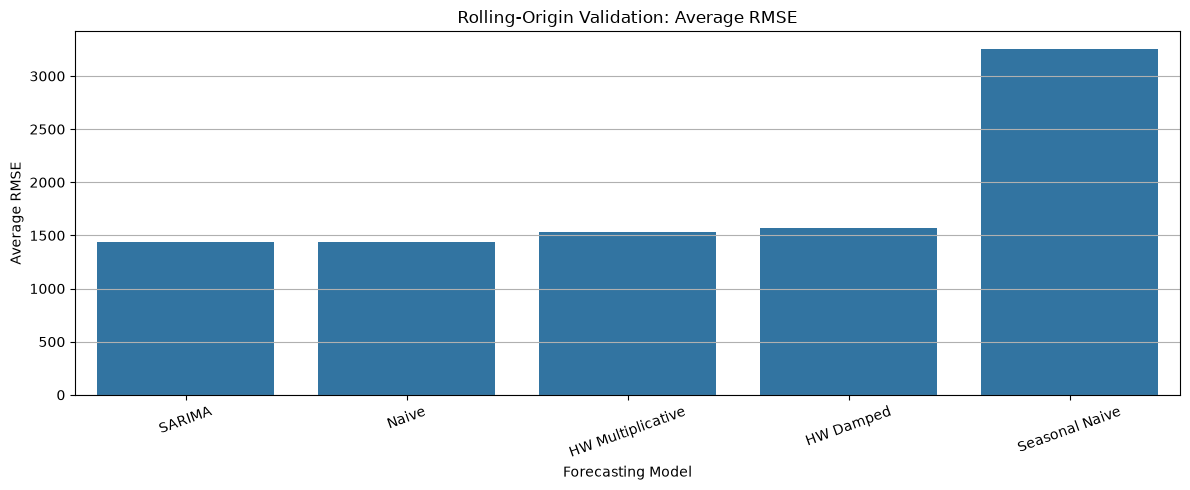

In [56]:
### Visualize model performance

plt.figure(figsize=(12, 5))

sns.barplot(
    data=rolling_summary,
    x='Model',
    y='RMSE'
)

plt.title('Rolling-Origin Validation: Average RMSE')
plt.xlabel('Forecasting Model')
plt.ylabel('Average RMSE')

plt.xticks(rotation=20)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

### Final model evaluation

In [57]:
### Evaluate the selected model

# Final test evaluation using selected Naive model

test_origins = [211, 223, 235]

test_results = []

for fold, origin in enumerate(test_origins, start=1):

    # Expanding historical training window
    fold_train = ts.iloc[:origin]

    # Next 12 months
    actual = ts.iloc[origin:origin + 12]

    # Naive forecast
    forecast = pd.Series(
        fold_train.iloc[-1],
        index=actual.index
    )

    # Calculate metrics
    mae = mean_absolute_error(actual, forecast)

    rmse = np.sqrt(
        mean_squared_error(actual, forecast)
    )

    mape = np.mean(
        np.abs((actual - forecast) / actual)
    ) * 100

    test_results.append({
        'Fold': fold,
        'Training Records': len(fold_train),
        'Test Start': actual.index.min(),
        'Test End': actual.index.max(),
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    })

test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(2))

,Fold,Training Records,Test Start,Test End,MAE,RMSE,MAPE
0,1,211,2022-08-01,2023-07-01,966.33,1006.92,14.02
1,2,223,2023-08-01,2024-07-01,5621.75,6741.68,38.05
2,3,235,2024-08-01,2025-07-01,1690.42,2093.78,13.41


In [59]:
test_summary = pd.DataFrame({
    'Metric': ['MAE', 'RMSE', 'MAPE'],
    'Average Test Score': [
        test_results_df['MAE'].mean(),
        test_results_df['RMSE'].mean(),
        test_results_df['MAPE'].mean()
    ]
})

display(test_summary.round(2))

,Metric,Average Test Score
0,MAE,2759.50
1,RMSE,3280.79
2,MAPE,21.83


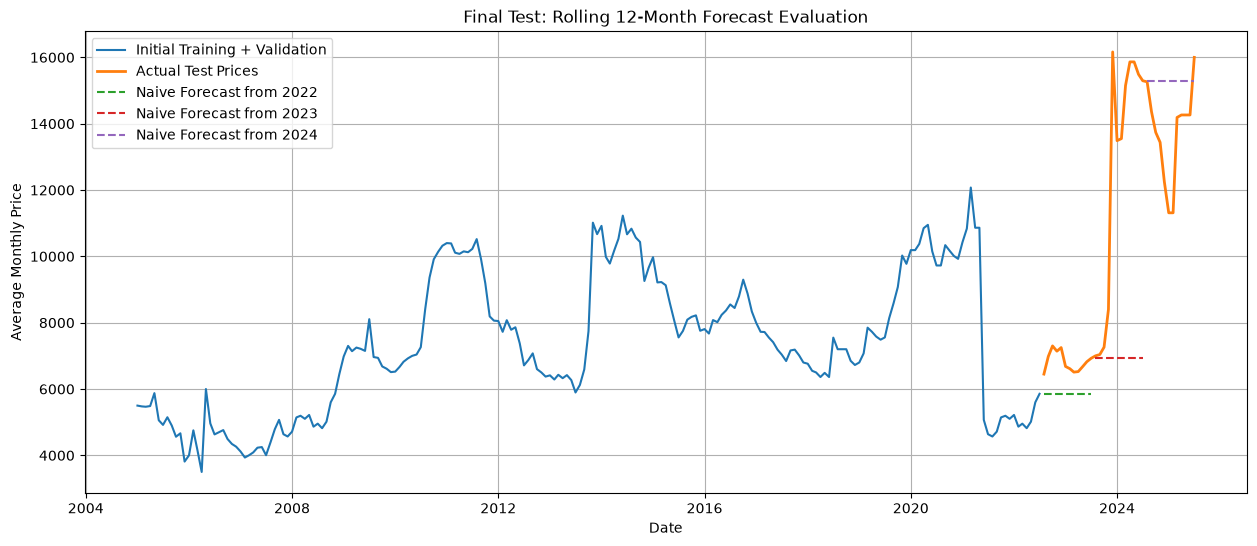

In [60]:
### Visualize final test predictions
plt.figure(figsize=(15, 6))

plt.plot(
    ts.iloc[:211],
    label='Initial Training + Validation'
)

plt.plot(
    ts.iloc[211:247],
    label='Actual Test Prices',
    linewidth=2
)

for origin in test_origins:

    fold_train = ts.iloc[:origin]
    actual = ts.iloc[origin:origin + 12]

    forecast = pd.Series(
        fold_train.iloc[-1],
        index=actual.index
    )

    plt.plot(
        forecast,
        linestyle='--',
        label=f'Naive Forecast from {actual.index[0].year}'
    )

plt.title('Final Test: Rolling 12-Month Forecast Evaluation')
plt.xlabel('Date')
plt.ylabel('Average Monthly Price')

plt.legend()
plt.grid(True)
plt.show()

### Generate the 12-month forecast





In [61]:
### Train on the complete historical dataset

# Fit the selected Naive model using all available data

final_train = ts.copy()

last_price = final_train.iloc[-1]
last_date = final_train.index[-1]

print("Final training observations:", len(final_train))
print("Last observed date:", last_date)
print("Last observed price:", last_price)

Final training observations: 249
Last observed date: 2025-09-01 00:00:00
Last observed price: 15750


In [62]:
### Generate the next 12 months

# Generate future monthly dates

future_dates = pd.date_range(
    start=last_date + pd.offsets.MonthBegin(1),
    periods=12,
    freq='MS'
)

# Naive forecast
future_predictions = pd.Series(
    [last_price] * 12,
    index=future_dates,
    name='predicted_avg_monthly_price'
)

# Create forecast dataframe
forecast_df = pd.DataFrame({
    'date': future_dates,
    'predicted_avg_monthly_price': future_predictions.values
})

display(forecast_df)

,date,predicted_avg_monthly_price
0,2025-10-01,15750
1,2025-11-01,15750
2,2025-12-01,15750
3,2026-01-01,15750
4,2026-02-01,15750
5,2026-03-01,15750
6,2026-04-01,15750
7,2026-05-01,15750
8,2026-06-01,15750
9,2026-07-01,15750


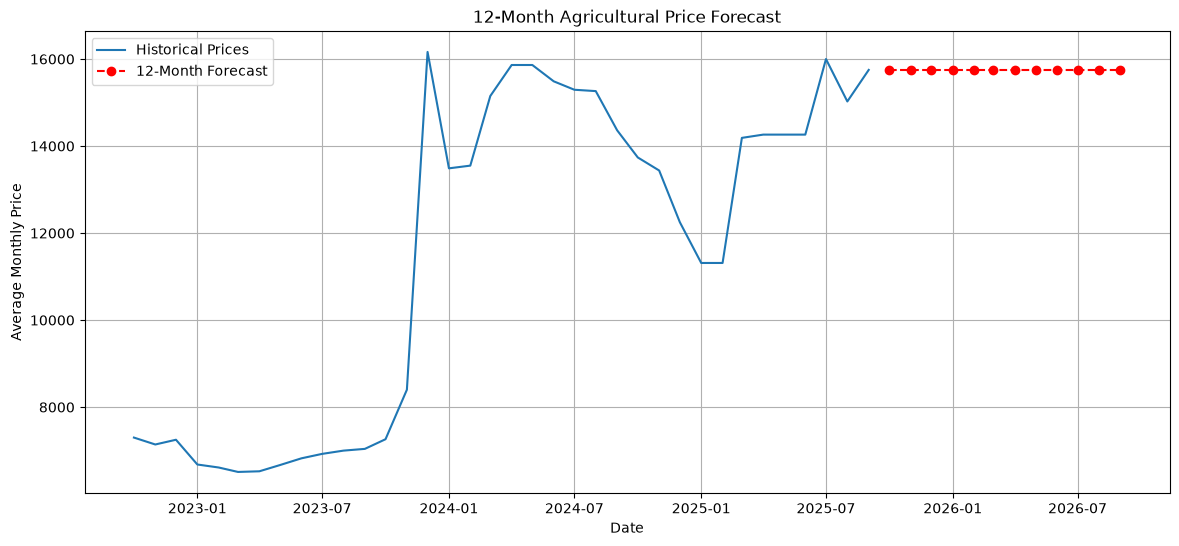

In [63]:
### Visualize the forecast

plt.figure(figsize=(14, 6))

plt.plot(
    ts.iloc[-36:],
    label='Historical Prices'
)

plt.plot(
    future_predictions,
    label='12-Month Forecast',
    color='red',
    linestyle='--',
    marker='o'
)

plt.title('12-Month Agricultural Price Forecast')
plt.xlabel('Date')
plt.ylabel('Average Monthly Price')

plt.legend()
plt.grid(True)
plt.show()

In [64]:
### Export the forecast

forecast_df.to_csv(
    '../outputs/12_month_price_forecast.csv',
    index=False
)

print("Forecast exported successfully!")

Forecast exported successfully!


The selected Naive forecasting model was used to generate predictions for the next 12 months. The model uses the most recent historical observation as the forecast value for all future periods. The last recorded price was 15,750 in September 2025. Consequently, the model predicts a constant monthly price of 15,750 from October 2025 to September 2026. Although the model demonstrated competitive performance during rolling-origin validation, its inability to anticipate sudden market changes is an important limitation.

### Fine-tuning Holt-Winters

In [66]:
### Create a hyperparameter search
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

# Use training + validation observations only
development_data = ts.iloc[:211]

# Three rolling validation origins
fold_origins = [174, 186, 198]

# Hyperparameter configurations
configs = []

for trend in [None, 'add']:

    for seasonal in [None, 'add', 'mul']:

        for damped in [False, True]:

            if trend is None and damped:
                continue

            configs.append({
                'trend': trend,
                'seasonal': seasonal,
                'damped_trend': damped
            })

print("Total configurations:", len(configs))

Total configurations: 9


In [67]:
### Evaluate each configuration

tuning_results = []

for config in configs:

    fold_errors = []

    for origin in fold_origins:

        fold_train = development_data.iloc[:origin]

        fold_actual = development_data.iloc[
            origin:origin + 12
        ]

        try:

            model = ExponentialSmoothing(
                fold_train,
                trend=config['trend'],
                seasonal=config['seasonal'],
                seasonal_periods=(
                    12 if config['seasonal'] else None
                ),
                damped_trend=config['damped_trend'],
                initialization_method='estimated'
            )

            fitted = model.fit(optimized=True)

            forecast = fitted.forecast(12)

            rmse = np.sqrt(
                mean_squared_error(
                    fold_actual,
                    forecast
                )
            )

            mae = mean_absolute_error(
                fold_actual,
                forecast
            )

            mape = np.mean(
                np.abs(
                    (fold_actual - forecast) / fold_actual
                )
            ) * 100

            fold_errors.append({
                'RMSE': rmse,
                'MAE': mae,
                'MAPE': mape
            })

        except Exception:
            continue

    if len(fold_errors) == len(fold_origins):

        tuning_results.append({
            'Trend': config['trend'],
            'Seasonal': config['seasonal'],
            'Damped': config['damped_trend'],
            'Average RMSE': np.mean(
                [x['RMSE'] for x in fold_errors]
            ),
            'Average MAE': np.mean(
                [x['MAE'] for x in fold_errors]
            ),
            'Average MAPE': np.mean(
                [x['MAPE'] for x in fold_errors]
            )
        })

tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    'Average RMSE'
).reset_index(drop=True)

display(tuning_df.round(2))

,Trend,Seasonal,Damped,Average RMSE,Average MAE,Average MAPE
0,add,NaN,True,1421.46,1088.06,12.86
1,add,NaN,False,1426.13,1065.28,12.72
2,add,add,False,1432.14,1035.07,12.99
3,NaN,NaN,False,1437.07,1101.17,12.99
4,NaN,mul,False,1449.40,1120.70,13.79
5,NaN,add,False,1455.88,1128.41,13.95
6,add,mul,False,1495.28,1150.96,14.16
7,add,mul,True,1532.00,1175.86,14.82
8,add,add,True,1571.28,1207.77,15.26


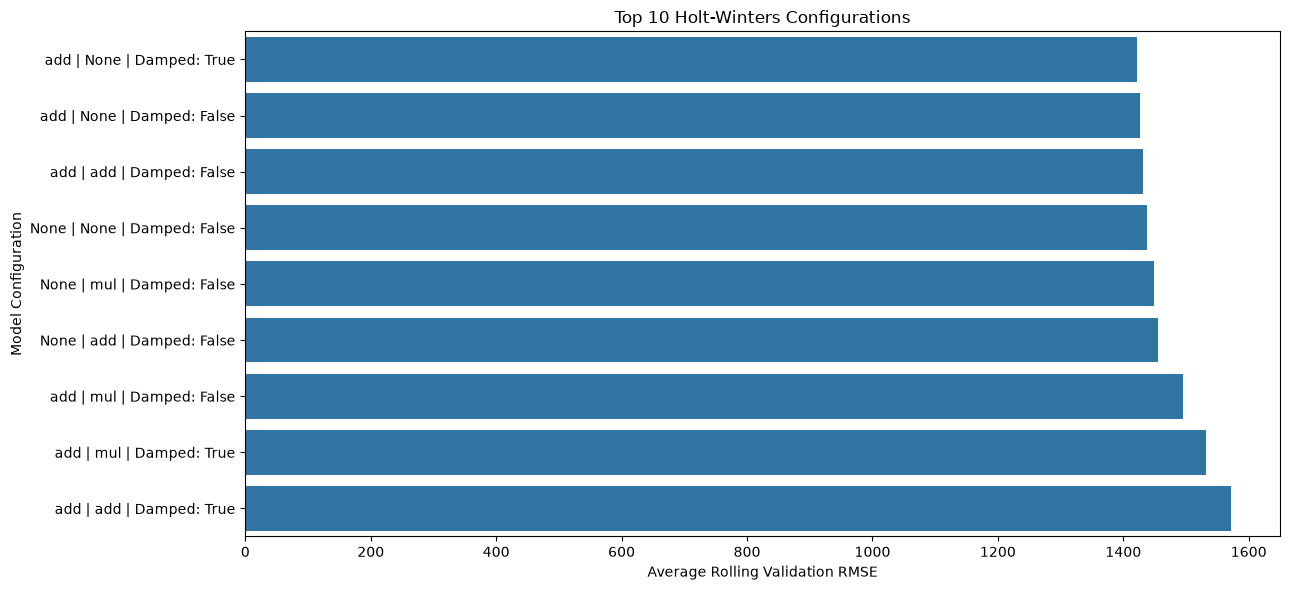

In [68]:
## Visualize the best configurations

import matplotlib.pyplot as plt
import seaborn as sns

top_models = tuning_df.head(10).copy()

top_models['Configuration'] = (
    top_models['Trend'].fillna('None')
    + ' | '
    + top_models['Seasonal'].fillna('None')
    + ' | Damped: '
    + top_models['Damped'].astype(str)
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=top_models,
    x='Average RMSE',
    y='Configuration'
)

plt.title('Top 10 Holt-Winters Configurations')
plt.xlabel('Average Rolling Validation RMSE')
plt.ylabel('Model Configuration')

plt.tight_layout()
plt.show()

In [1]:
### Fine-tune SARIMA


#Import libraries

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

In [ ]:
### Define SARIMA configurations

sarima_configs = []

# Non-seasonal configurations
for p in [0, 1, 2]:
    for q in [0, 1, 2]:
        sarima_configs.append({
            'order': (p, 1, q),
            'seasonal_order': (0, 0, 0, 12)
        })

# Seasonal configurations
seasonal_options = [
    (0, 1, 1, 12),
    (1, 1, 0, 12),
    (1, 1, 1, 12)
]

for p, q in [(0, 1), (1, 0), (1, 1)]:

    for seasonal_order in seasonal_options:

        sarima_configs.append({
            'order': (p, 1, q),
            'seasonal_order': seasonal_order
        })

print("Total SARIMA configurations:", len(sarima_configs))

Total SARIMA configurations: 18


In [2]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Load dataset
df = pd.read_csv("../data/price_data.csv")

# Convert date column
df['date'] = pd.to_datetime(df['date'])

# Sort chronologically
df = df.sort_values('date')

# Create monthly time series
ts = df.set_index('date')['avg_monthly_price']
ts = ts.asfreq('MS')

# Verify
print("Dataset loaded successfully!")
print("DataFrame shape:", df.shape)
print("Time series observations:", len(ts))
print("Start:", ts.index.min())
print("End:", ts.index.max())

display(df.head())

Dataset loaded successfully!
DataFrame shape: (249, 2)
Time series observations: 249
Start: 2005-01-01 00:00:00
End: 2025-09-01 00:00:00


,date,avg_monthly_price
0,2005-01-01,5500
1,2005-02-01,5476
2,2005-03-01,5466
3,2005-04-01,5487
4,2005-05-01,5876


In [3]:
development_data = ts.iloc[:211]

fold_origins = [174, 186, 198]

print("Development observations:", len(development_data))

for i, origin in enumerate(fold_origins, 1):
    print(
        f"Fold {i}:",
        development_data.index[origin],
        "to",
        development_data.index[origin + 11]
    )

Development observations: 211
Fold 1: 2019-07-01 00:00:00 to 2020-06-01 00:00:00
Fold 2: 2020-07-01 00:00:00 to 2021-06-01 00:00:00
Fold 3: 2021-07-01 00:00:00 to 2022-06-01 00:00:00


In [11]:
### Perform rolling-origin SARIMA tuning

development_data = ts.iloc[:211]

fold_origins = [174, 186, 198]

sarima_tuning_results = []

for config in sarima_configs:

    fold_metrics = []

    for origin in fold_origins:

        fold_train = development_data.iloc[:origin]

        fold_actual = development_data.iloc[
            origin:origin + 12
        ]

        try:

            model = SARIMAX(
                fold_train,
                order=config['order'],
                seasonal_order=config['seasonal_order'],
                enforce_stationarity=False,
                enforce_invertibility=False
            )

            fitted = model.fit(
                disp=False,
                maxiter=300
            )

            forecast = fitted.forecast(steps=12)

            mae = mean_absolute_error(
                fold_actual,
                forecast
            )

            rmse = np.sqrt(
                mean_squared_error(
                    fold_actual,
                    forecast
                )
            )

            mape = np.mean(
                np.abs(
                    (fold_actual - forecast) / fold_actual
                )
            ) * 100

            fold_metrics.append({
                'MAE': mae,
                'RMSE': rmse,
                'MAPE': mape
            })

        except Exception as e:
            print("Configuration failed:", config, e)
            break

    if len(fold_metrics) == 3:

        sarima_tuning_results.append({

            'Order': str(config['order']),

            'Seasonal Order': str(
                config['seasonal_order']
            ),

            'Average MAE': np.mean([
                x['MAE'] for x in fold_metrics
            ]),

            'Average RMSE': np.mean([
                x['RMSE'] for x in fold_metrics
            ]),

            'Average MAPE': np.mean([
                x['MAPE'] for x in fold_metrics
            ])
        })

sarima_tuning_df = pd.DataFrame(
    sarima_tuning_results
)

sarima_tuning_df = sarima_tuning_df.sort_values(
    'Average RMSE'
).reset_index(drop=True)

display(sarima_tuning_df.round(2))

,Order,Seasonal Order,Average MAE,Average RMSE,Average MAPE
0,"(0, 1, 1)","(0, 1, 1, 12)",1034.80,1435.32,12.58
1,"(0, 1, 1)","(0, 0, 0, 12)",1104.25,1436.71,12.95
2,"(0, 1, 0)","(0, 0, 0, 12)",1101.17,1437.07,12.99
3,"(1, 1, 0)","(0, 0, 0, 12)",1110.34,1445.49,13.05
4,"(0, 1, 1)","(1, 1, 1, 12)",1071.14,1450.68,12.86
5,"(1, 1, 0)","(1, 1, 1, 12)",1075.46,1462.25,12.89
6,"(1, 1, 0)","(0, 1, 1, 12)",1058.09,1467.87,12.99
7,"(1, 1, 1)","(0, 0, 0, 12)",1158.23,1490.98,14.04
8,"(2, 1, 1)","(0, 0, 0, 12)",1305.98,1634.07,16.84
9,"(1, 1, 1)","(1, 1, 1, 12)",1268.88,1637.13,16.66


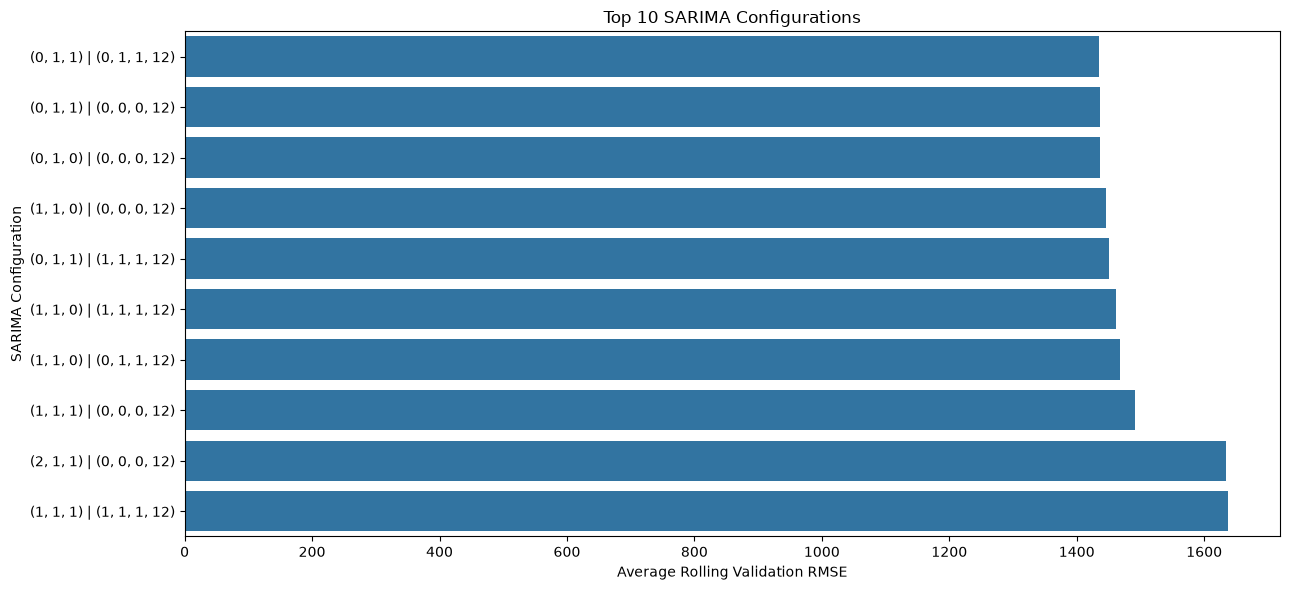

In [12]:
### Visualize the top SARIMA models

top_sarima = sarima_tuning_df.head(10).copy()

top_sarima['Configuration'] = (
    top_sarima['Order']
    + ' | '
    + top_sarima['Seasonal Order']
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=top_sarima,
    x='Average RMSE',
    y='Configuration'
)

plt.title('Top 10 SARIMA Configurations')
plt.xlabel('Average Rolling Validation RMSE')
plt.ylabel('SARIMA Configuration')

plt.tight_layout()
plt.show()

In [13]:
## Comparing the three models fold by fold

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

development_data = ts.iloc[:211]

fold_origins = [174, 186, 198]

comparison_results = []

for fold, origin in enumerate(fold_origins, 1):

    fold_train = development_data.iloc[:origin]

    actual = development_data.iloc[origin:origin+12]

    models = {}

    # Model 1: Holt-Winters Damped
    hw = ExponentialSmoothing(
        fold_train,
        trend='add',
        damped_trend=True,
        seasonal=None,
        initialization_method='estimated'
    ).fit(optimized=True)

    models['HW Additive Damped'] = hw.forecast(12)

    # Model 2: Best SARIMA
    sarima = SARIMAX(
        fold_train,
        order=(0, 1, 1),
        seasonal_order=(0, 1, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(disp=False, maxiter=300)

    models['SARIMA'] = sarima.forecast(12)

    # Model 3: Naive
    models['Naive'] = pd.Series(
        fold_train.iloc[-1],
        index=actual.index
    )

    for name, prediction in models.items():

        mae = mean_absolute_error(actual, prediction)

        rmse = np.sqrt(
            mean_squared_error(actual, prediction)
        )

        mape = np.mean(
            np.abs((actual - prediction) / actual)
        ) * 100

        comparison_results.append({
            'Fold': fold,
            'Model': name,
            'MAE': mae,
            'RMSE': rmse,
            'MAPE': mape
        })

fold_comparison = pd.DataFrame(comparison_results)

display(fold_comparison.round(2))

,Fold,Model,MAE,RMSE,MAPE
0,1,HW Additive Damped,2124.75,2353.29,21.04
1,1,SARIMA,1962.45,2188.85,19.40
2,1,Naive,2166.83,2399.86,21.46
3,2,HW Additive Damped,902.98,1620.85,12.73
4,2,SARIMA,838.08,1647.04,12.46
5,2,Naive,901.58,1621.33,12.72
6,3,HW Additive Damped,236.45,290.24,4.82
7,3,SARIMA,303.88,470.07,5.89
8,3,Naive,235.08,290.03,4.78


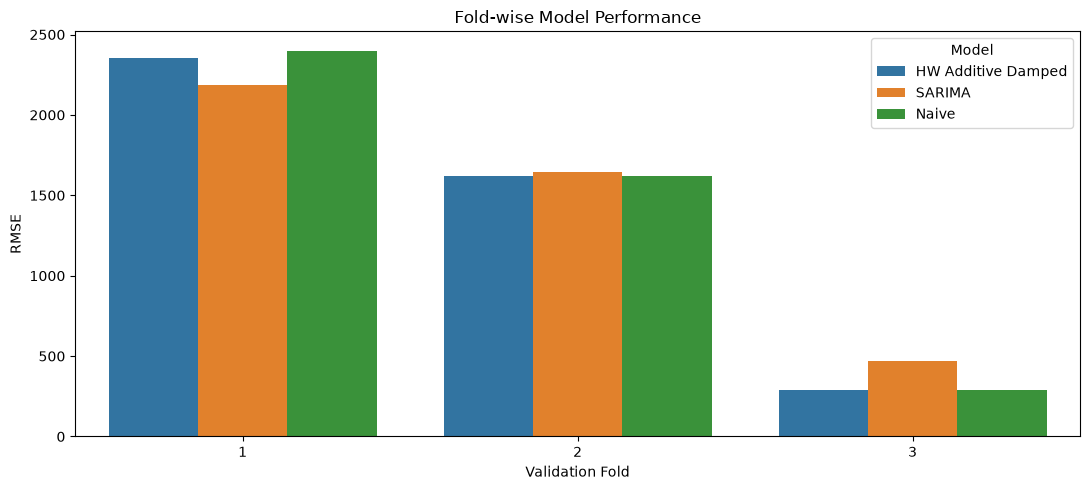

In [14]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=fold_comparison,
    x='Fold',
    y='RMSE',
    hue='Model'
)

plt.title('Fold-wise Model Performance')
plt.ylabel('RMSE')
plt.xlabel('Validation Fold')

plt.tight_layout()
plt.show()

### Random Forest forecasting

In [16]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

import numpy as np
import pandas as pd

In [17]:
### Create time-series features

def create_features(series):

    data = pd.DataFrame(index=series.index)

    # Lag features
    for lag in [1, 2, 3, 6, 12]:
        data[f'lag_{lag}'] = series.shift(lag)

    # Rolling averages (shifted to avoid leakage)
    for window in [3, 6, 12]:
        data[f'rolling_mean_{window}'] = (
            series.shift(1)
            .rolling(window=window)
            .mean()
        )

    # Calendar features
    month = series.index.month

    data['month_sin'] = np.sin(
        2 * np.pi * month / 12
    )

    data['month_cos'] = np.cos(
        2 * np.pi * month / 12
    )

    data['target'] = series

    return data.dropna()

In [18]:
###inspecting genarated features 

rf_features = create_features(ts)

print("Feature dataset shape:", rf_features.shape)

display(rf_features.head())

Feature dataset shape: (237, 11)


,lag_1,lag_2,lag_3,lag_6,lag_12,rolling_mean_3,rolling_mean_6,rolling_mean_12,month_sin,month_cos,target
date,,,,,,,,,,,
2006-01-01,3813.0,4665.0,4562.0,4919.0,5500.0,4346.666667,4667.833333,5072.500000,0.500000,8.660254e-01,4000
2006-02-01,4000.0,3813.0,4665.0,5149.0,5476.0,4159.333333,4514.666667,4947.500000,0.866025,5.000000e-01,4755
2006-03-01,4755.0,4000.0,3813.0,4899.0,5466.0,4189.333333,4449.000000,4887.416667,1.000000,6.123234e-17,4176
2006-04-01,4176.0,4755.0,4000.0,4562.0,5487.0,4310.333333,4328.500000,4779.916667,0.866025,-5.000000e-01,3500
2006-05-01,3500.0,4176.0,4755.0,4665.0,5876.0,4143.666667,4151.500000,4614.333333,0.500000,-8.660254e-01,6000


In [19]:
### Creating recursive forecasting function

def rf_forecast(model, history, future_dates):

    predictions = []

    history_values = list(history.values)

    for date in future_dates:

        features = {}

        # Lag features
        for lag in [1, 2, 3, 6, 12]:
            features[f'lag_{lag}'] = history_values[-lag]

        # Rolling averages
        for window in [3, 6, 12]:
            features[f'rolling_mean_{window}'] = np.mean(
                history_values[-window:]
            )

        # Calendar features
        month = date.month

        features['month_sin'] = np.sin(
            2 * np.pi * month / 12
        )

        features['month_cos'] = np.cos(
            2 * np.pi * month / 12
        )

        X_future = pd.DataFrame([features])

        prediction = model.predict(X_future)[0]

        predictions.append(prediction)

        # Add prediction for the next recursive step
        history_values.append(prediction)

    return pd.Series(
        predictions,
        index=future_dates
    )

In [20]:
### Evaluating Random Forest using rolling-origin validation

development_data = ts.iloc[:211]

fold_origins = [174, 186, 198]

rf_results = []
rf_predictions = {}

for fold, origin in enumerate(fold_origins, 1):

    fold_train = development_data.iloc[:origin]

    actual = development_data.iloc[origin:origin+12]

    # Create training features using only fold training data
    train_features = create_features(fold_train)

    X_train = train_features.drop(columns=['target'])
    y_train = train_features['target']

    # Initialize Random Forest
    rf_model = RandomForestRegressor(
        n_estimators=300,
        max_depth=8,
        min_samples_split=4,
        min_samples_leaf=2,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    )

    rf_model.fit(X_train, y_train)

    # Forecast next 12 months recursively
    predictions = rf_forecast(
        rf_model,
        fold_train,
        actual.index
    )

    rf_predictions[fold] = predictions

    # Evaluation
    mae = mean_absolute_error(actual, predictions)

    rmse = np.sqrt(
        mean_squared_error(actual, predictions)
    )

    mape = np.mean(
        np.abs((actual - predictions) / actual)
    ) * 100

    rf_results.append({
        'Fold': fold,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    })

rf_results_df = pd.DataFrame(rf_results)

display(rf_results_df.round(2))

,Fold,MAE,RMSE,MAPE
0,1,2441.07,2674.51,24.26
1,2,1216.11,1608.11,14.11
2,3,1805.29,1818.71,36.35


In [21]:
### Calculate average performance

rf_summary = pd.DataFrame({
    'Model': ['Random Forest'],
    'Average MAE': [rf_results_df['MAE'].mean()],
    'Average RMSE': [rf_results_df['RMSE'].mean()],
    'Average MAPE': [rf_results_df['MAPE'].mean()]
})

display(rf_summary.round(2))

,Model,Average MAE,Average RMSE,Average MAPE
0,Random Forest,1820.82,2033.78,24.91


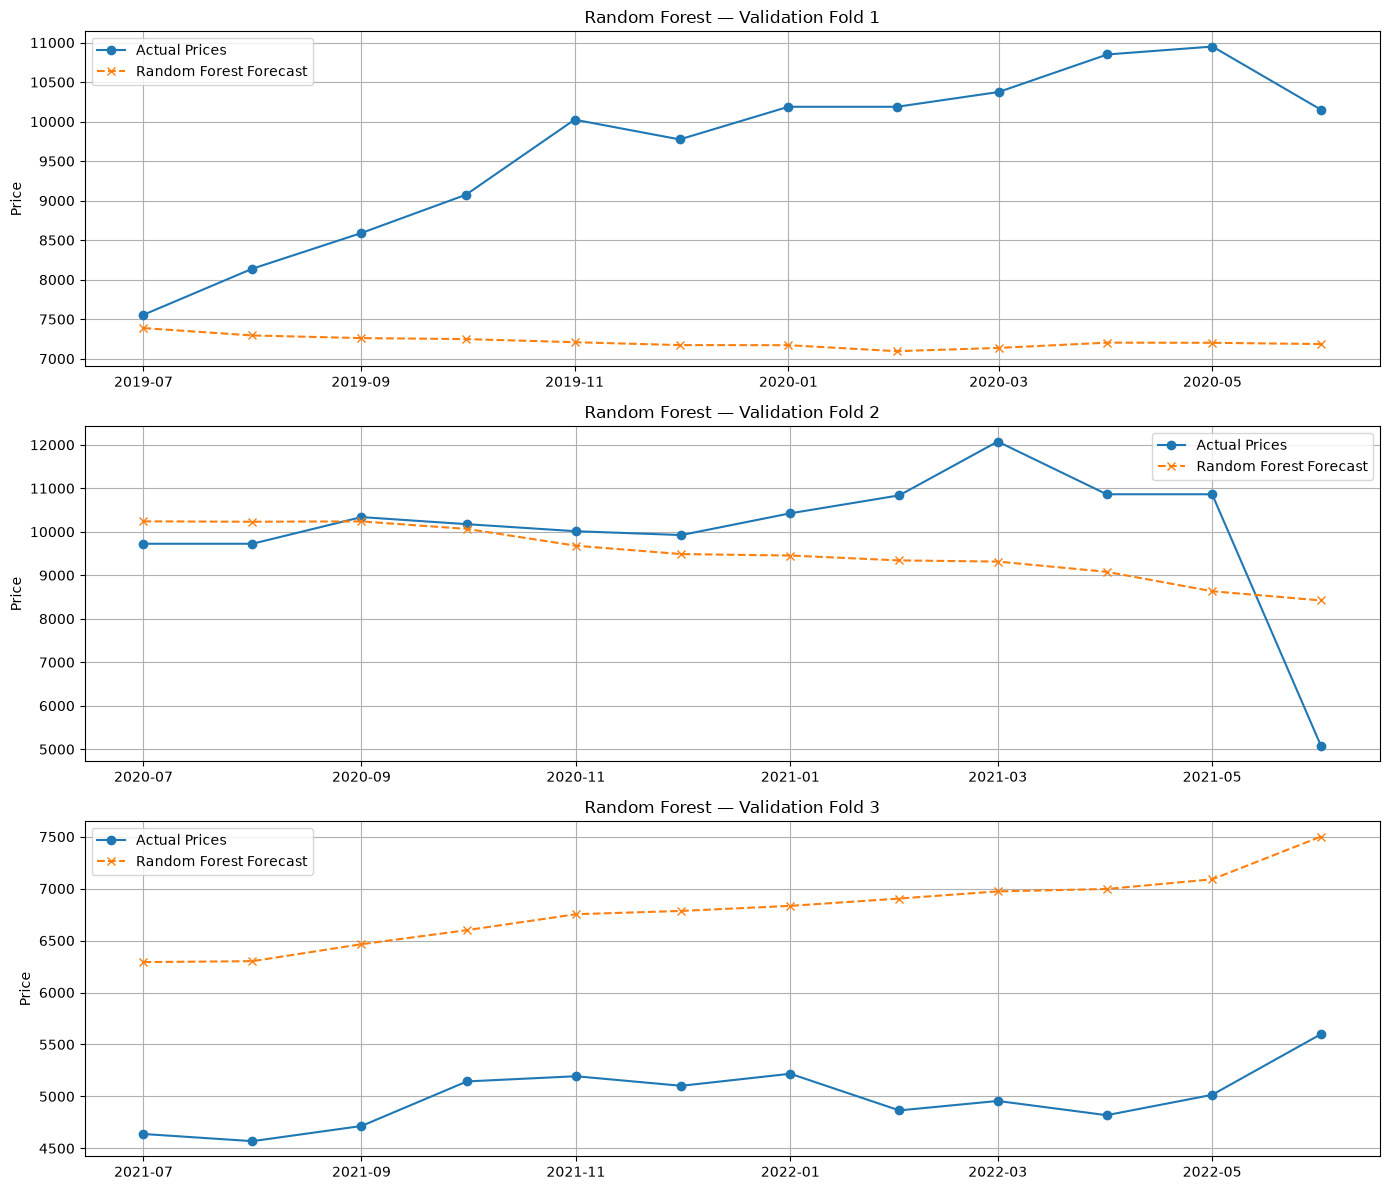

In [22]:
### Visualize Random Forest predictions
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

for i, fold in enumerate([1, 2, 3]):

    origin = fold_origins[fold-1]

    actual = development_data.iloc[origin:origin+12]

    axes[i].plot(
        actual.index,
        actual.values,
        marker='o',
        label='Actual Prices'
    )

    axes[i].plot(
        rf_predictions[fold].index,
        rf_predictions[fold].values,
        marker='x',
        linestyle='--',
        label='Random Forest Forecast'
    )

    axes[i].set_title(f'Random Forest — Validation Fold {fold}')
    axes[i].set_ylabel('Price')
    axes[i].legend()
    axes[i].grid(True)

plt.tight_layout()
plt.show()

In [23]:
### Random Forest hyperparameter tuning
from sklearn.model_selection import ParameterGrid
from sklearn.ensemble import RandomForestRegressor

param_grid = {
    'n_estimators': [200, 300, 500],
    'max_depth': [4, 6, 8, 12, None],
    'min_samples_split': [2, 4, 6],
    'min_samples_leaf': [1, 2, 4],
    'max_features': [0.7, 1.0]
}

print("Total configurations:", len(list(ParameterGrid(param_grid))))

Total configurations: 270


In [24]:
### Run rolling-origin hyperparameter tuning

tuning_results = []

for params in ParameterGrid(param_grid):

    fold_rmse = []
    fold_mae = []

    for fold, origin in enumerate(fold_origins, 1):

        fold_train = development_data.iloc[:origin]
        actual = development_data.iloc[origin:origin+12]

        train_features = create_features(fold_train)

        X_train = train_features.drop(columns=['target'])
        y_train = train_features['target']

        model = RandomForestRegressor(
            **params,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, y_train)

        predictions = rf_forecast(
            model,
            fold_train,
            actual.index
        )

        fold_rmse.append(
            np.sqrt(mean_squared_error(actual, predictions))
        )

        fold_mae.append(
            mean_absolute_error(actual, predictions)
        )

    tuning_results.append({
        **params,
        'Average_RMSE': np.mean(fold_rmse),
        'Average_MAE': np.mean(fold_mae)
    })

rf_tuning_df = pd.DataFrame(tuning_results)

rf_tuning_df = rf_tuning_df.sort_values(
    'Average_RMSE'
).reset_index(drop=True)

display(rf_tuning_df.head(10).round(2))

,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators,Average_RMSE,Average_MAE
0,NaN,1.0,4,2,500,1918.53,1674.43
1,NaN,1.0,4,6,500,1918.53,1674.43
2,NaN,1.0,4,4,500,1918.53,1674.43
3,12.0,1.0,4,6,500,1918.53,1674.43
4,8.0,1.0,4,6,500,1918.53,1674.43
5,8.0,1.0,4,2,500,1918.53,1674.43
6,12.0,1.0,4,2,500,1918.53,1674.43
7,12.0,1.0,4,4,500,1918.53,1674.43
8,8.0,1.0,4,4,500,1918.53,1674.43
9,NaN,1.0,4,2,300,1920.58,1677.39


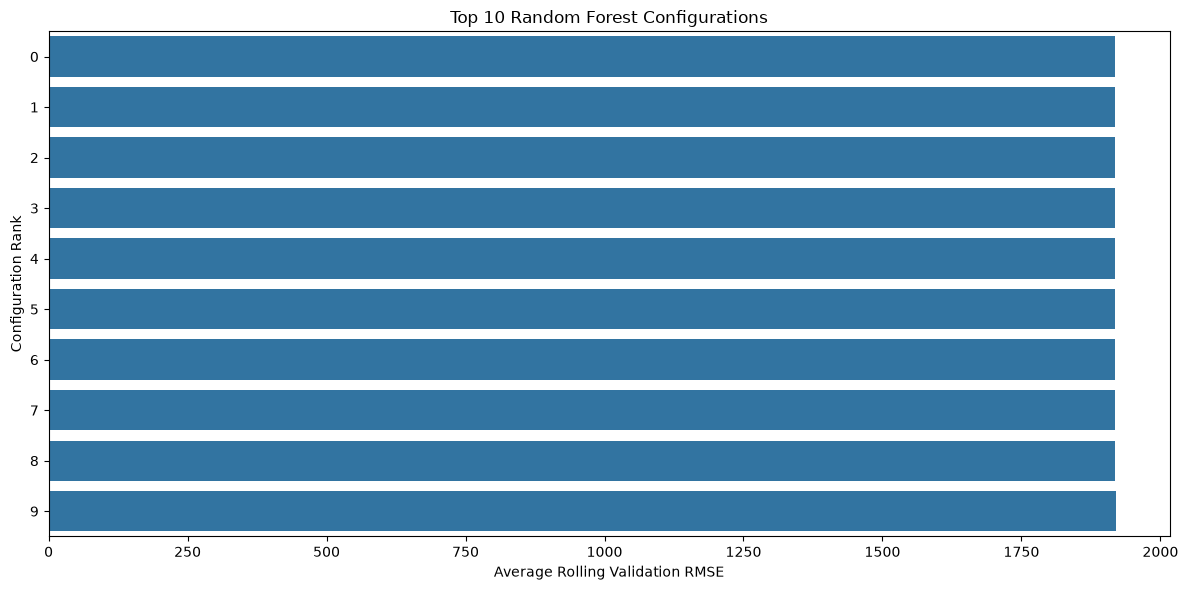

In [25]:
### Plot the top 10 configurations

top10_rf = rf_tuning_df.head(10).copy()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top10_rf,
    x='Average_RMSE',
    y=top10_rf.index.astype(str)
)

plt.title('Top 10 Random Forest Configurations')
plt.xlabel('Average Rolling Validation RMSE')
plt.ylabel('Configuration Rank')

plt.tight_layout()
plt.show()


In [27]:
best_rf_params = {
    'n_estimators': 500,
    'max_depth': None,
    'min_samples_split': 4,
    'min_samples_leaf': 1,
    'max_features': 1.0
}

In [28]:
### Evaluate the tuned Random Forest

best_rf_results = []
best_rf_predictions = {}

for fold, origin in enumerate(fold_origins, 1):

    fold_train = development_data.iloc[:origin]
    actual = development_data.iloc[origin:origin+12]

    train_features = create_features(fold_train)

    X_train = train_features.drop(columns=['target'])
    y_train = train_features['target']

    model = RandomForestRegressor(
        **best_rf_params,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    predictions = rf_forecast(
        model,
        fold_train,
        actual.index
    )

    best_rf_predictions[fold] = predictions

    best_rf_results.append({
        'Fold': fold,
        'MAE': mean_absolute_error(actual, predictions),
        'RMSE': np.sqrt(mean_squared_error(actual, predictions)),
        'MAPE': np.mean(
            np.abs((actual - predictions) / actual)
        ) * 100
    })

best_rf_df = pd.DataFrame(best_rf_results)

display(best_rf_df.round(2))

,Fold,MAE,RMSE,MAPE
0,1,2478.56,2715.60,24.64
1,2,1221.41,1595.76,14.09
2,3,1874.91,1890.22,37.79


### XGBoost forecasting

In [30]:
import importlib.util

if importlib.util.find_spec("xgboost") is None:
    print("XGBoost is not installed.")
else:
    import xgboost
    print("XGBoost version:", xgboost.__version__)

XGBoost version: 3.4.1


In [31]:
### Import XGBoost

from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

import numpy as np
import pandas as pd

In [32]:
## Train and evaluate XGBoost

xgb_results = []
xgb_predictions = {}
xgb_models = {}

for fold, origin in enumerate(fold_origins, 1):

    fold_train = development_data.iloc[:origin]
    actual = development_data.iloc[origin:origin+12]

    # Create training features
    train_features = create_features(fold_train)

    X_train = train_features.drop(columns=['target'])
    y_train = train_features['target']

    # Initialize XGBoost
    xgb_model = XGBRegressor(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=3,
        reg_alpha=0.1,
        reg_lambda=5,
        objective='reg:squarederror',
        random_state=42,
        n_jobs=-1
    )

    # Train
    xgb_model.fit(X_train, y_train)

    # Recursive 12-month forecast
    predictions = rf_forecast(
        xgb_model,
        fold_train,
        actual.index
    )

    xgb_models[fold] = xgb_model
    xgb_predictions[fold] = predictions

    # Evaluation
    mae = mean_absolute_error(actual, predictions)

    rmse = np.sqrt(
        mean_squared_error(actual, predictions)
    )

    mape = np.mean(
        np.abs((actual - predictions) / actual)
    ) * 100

    xgb_results.append({
        'Fold': fold,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    })

xgb_results_df = pd.DataFrame(xgb_results)

display(xgb_results_df.round(2))

,Fold,MAE,RMSE,MAPE
0,1,2608.02,2855.02,25.94
1,2,1322.00,1751.29,14.58
2,3,1645.55,1664.91,33.33


In [33]:
### Calculate average performance

xgb_summary = pd.DataFrame({
    'Model': ['XGBoost'],
    'Average MAE': [xgb_results_df['MAE'].mean()],
    'Average RMSE': [xgb_results_df['RMSE'].mean()],
    'Average MAPE': [xgb_results_df['MAPE'].mean()]
})

display(xgb_summary.round(2))

,Model,Average MAE,Average RMSE,Average MAPE
0,XGBoost,1858.52,2090.41,24.61


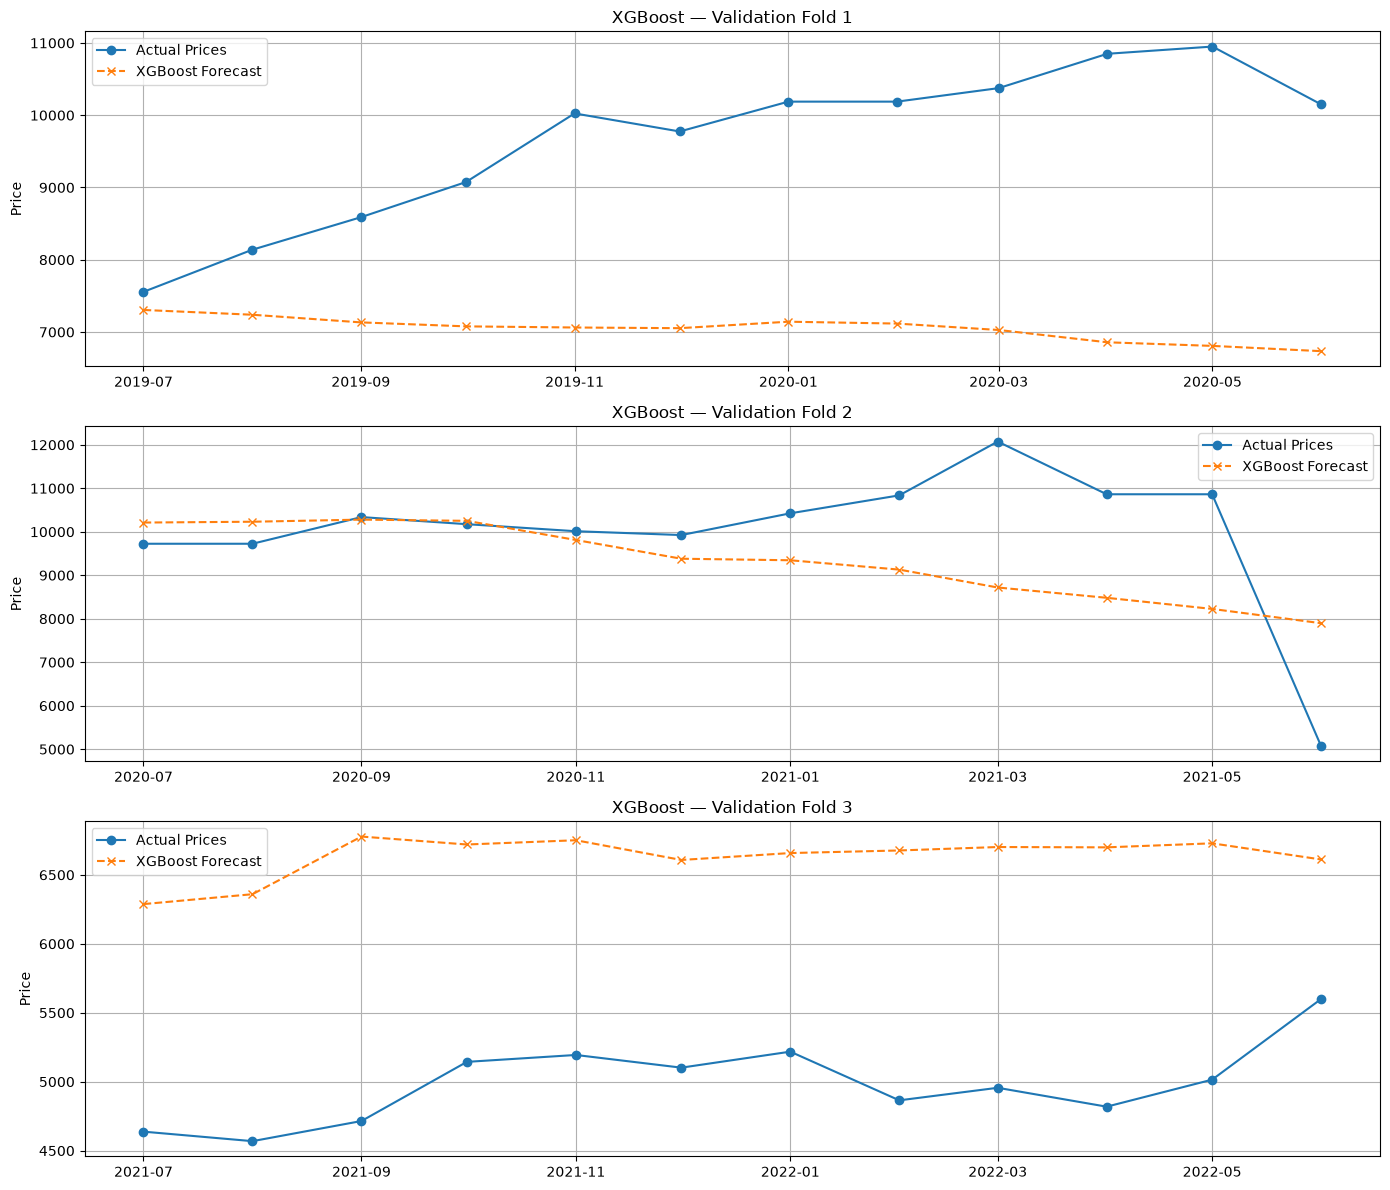

In [34]:
### Visualize predictions

fig, axes = plt.subplots(3, 1, figsize=(14, 12))

for i, fold in enumerate([1, 2, 3]):

    origin = fold_origins[fold-1]

    actual = development_data.iloc[origin:origin+12]

    axes[i].plot(
        actual.index,
        actual.values,
        marker='o',
        label='Actual Prices'
    )

    axes[i].plot(
        xgb_predictions[fold].index,
        xgb_predictions[fold].values,
        marker='x',
        linestyle='--',
        label='XGBoost Forecast'
    )

    axes[i].set_title(f'XGBoost — Validation Fold {fold}')
    axes[i].set_ylabel('Price')
    axes[i].legend()
    axes[i].grid(True)

plt.tight_layout()
plt.show()

In [35]:
### Compare against existing models

model_comparison = pd.DataFrame([
    {
        'Model': 'HW Additive Damped',
        'RMSE': 1421.46
    },
    {
        'Model': 'SARIMA',
        'RMSE': 1435.32
    },
    {
        'Model': 'Naive',
        'RMSE': 1437.07
    },
    {
        'Model': 'Random Forest',
        'RMSE': 2033.78
    },
    {
        'Model': 'XGBoost',
        'RMSE': xgb_results_df['RMSE'].mean()
    }
])

display(
    model_comparison.sort_values('RMSE').round(2)
)

,Model,RMSE
0,HW Additive Damped,1421.46
1,SARIMA,1435.32
2,Naive,1437.07
3,Random Forest,2033.78
4,XGBoost,2090.41


In [36]:
### XGBoost hyperparameter tuning
from sklearn.model_selection import ParameterGrid
from xgboost import XGBRegressor

xgb_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [1, 2, 3],
    'learning_rate': [0.01, 0.03, 0.05],
    'subsample': [0.7, 0.9],
    'colsample_bytree': [0.7, 0.9],
    'min_child_weight': [3, 5],
    'reg_alpha': [0.1, 1],
    'reg_lambda': [5, 10]
}

print(
    "Total configurations:",
    len(list(ParameterGrid(xgb_param_grid)))
)

Total configurations: 864


In [37]:
xgb_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [1, 2, 3],
    'learning_rate': [0.01, 0.03],
    'min_child_weight': [3, 5],
    'reg_lambda': [5, 10]
}

print("Configurations:", len(list(ParameterGrid(xgb_param_grid))))

Configurations: 72


In [38]:
### Execute rolling-origin tuning

xgb_tuning_results = []

for params in ParameterGrid(xgb_param_grid):

    fold_rmse = []
    fold_mae = []

    for fold, origin in enumerate(fold_origins, 1):

        fold_train = development_data.iloc[:origin]
        actual = development_data.iloc[origin:origin+12]

        train_features = create_features(fold_train)

        X_train = train_features.drop(columns=['target'])
        y_train = train_features['target']

        model = XGBRegressor(
            **params,
            objective='reg:squarederror',
            random_state=42,
            n_jobs=-1,
            verbosity=0
        )

        model.fit(X_train, y_train)

        predictions = rf_forecast(
            model,
            fold_train,
            actual.index
        )

        fold_rmse.append(
            np.sqrt(mean_squared_error(actual, predictions))
        )

        fold_mae.append(
            mean_absolute_error(actual, predictions)
        )

    xgb_tuning_results.append({
        **params,
        'Average_RMSE': np.mean(fold_rmse),
        'Average_MAE': np.mean(fold_mae)
    })

xgb_tuning_df = pd.DataFrame(xgb_tuning_results)

xgb_tuning_df = xgb_tuning_df.sort_values(
    'Average_RMSE'
).reset_index(drop=True)

display(xgb_tuning_df.head(10).round(2))

,learning_rate,max_depth,min_child_weight,n_estimators,reg_lambda,Average_RMSE,Average_MAE
0,0.03,2,3,300,5,1935.02,1708.11
1,0.03,1,5,300,10,1940.80,1661.66
2,0.03,1,5,300,5,1958.96,1682.76
3,0.03,1,5,200,5,1978.46,1660.87
4,0.03,2,5,200,10,1990.91,1771.74
5,0.03,2,3,200,10,1993.90,1773.32
6,0.03,2,5,300,10,1997.14,1771.46
7,0.03,1,5,200,10,1997.53,1680.46
8,0.03,1,3,300,5,1997.82,1724.68
9,0.03,2,3,300,10,1998.75,1773.37


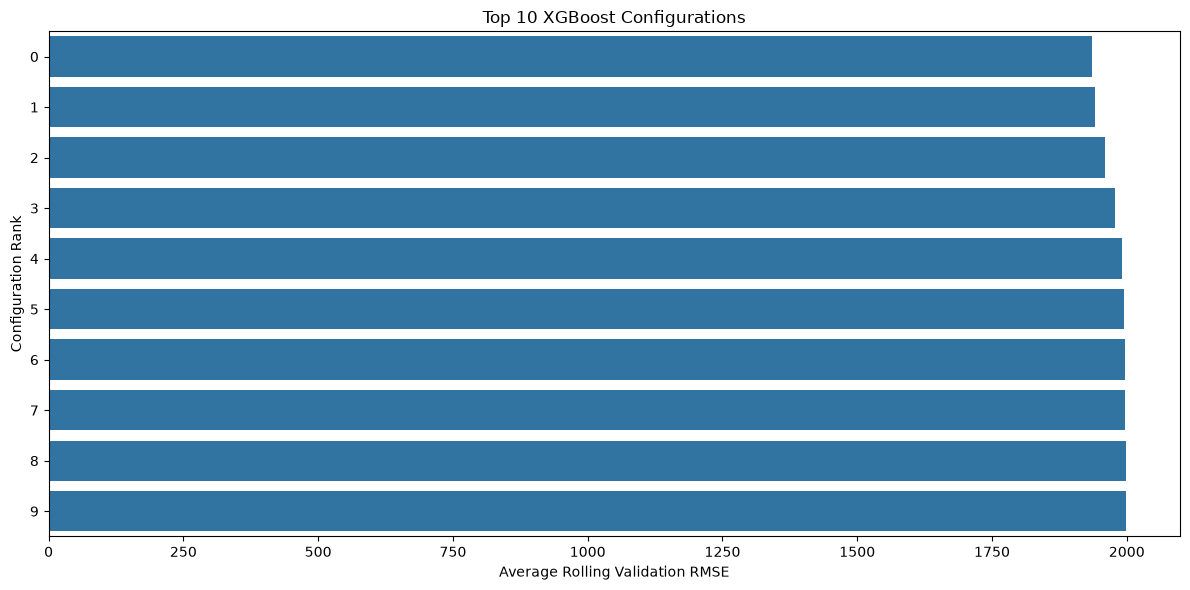

In [39]:
### Plot the top configurations

top10_xgb = xgb_tuning_df.head(10).copy()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top10_xgb,
    x='Average_RMSE',
    y=top10_xgb.index.astype(str)
)

plt.title('Top 10 XGBoost Configurations')
plt.xlabel('Average Rolling Validation RMSE')
plt.ylabel('Configuration Rank')

plt.tight_layout()
plt.show()

In [40]:
### Improved feature engineering

def create_advanced_features(series):

    data = pd.DataFrame(index=series.index)

    # Lag features
    for lag in [1, 2, 3, 4, 6, 9, 12]:
        data[f'lag_{lag}'] = series.shift(lag)

    # Rolling statistics
    for window in [3, 6, 12]:
        shifted = series.shift(1)

        data[f'rolling_mean_{window}'] = (
            shifted.rolling(window).mean()
        )

        data[f'rolling_std_{window}'] = (
            shifted.rolling(window).std()
        )

        data[f'rolling_min_{window}'] = (
            shifted.rolling(window).min()
        )

        data[f'rolling_max_{window}'] = (
            shifted.rolling(window).max()
        )

    # Momentum
    data['momentum_1'] = series.shift(1) - series.shift(2)
    data['momentum_3'] = series.shift(1) - series.shift(4)
    data['momentum_6'] = series.shift(1) - series.shift(7)

    # Percentage change
    data['pct_change_1'] = series.shift(1).pct_change(1)
    data['pct_change_3'] = series.shift(1).pct_change(3)

    # Calendar features
    month = series.index.month

    data['month_sin'] = np.sin(2 * np.pi * month / 12)
    data['month_cos'] = np.cos(2 * np.pi * month / 12)

    data['target'] = series

    return data.replace([np.inf, -np.inf], np.nan).dropna()

In [41]:
### Inspect advanced features

advanced_features = create_advanced_features(ts)

print("Advanced feature shape:", advanced_features.shape)

display(advanced_features.head())

Advanced feature shape: (237, 27)


,lag_1,lag_2,lag_3,lag_4,lag_6,lag_9,lag_12,rolling_mean_3,rolling_std_3,rolling_min_3,...,rolling_min_12,rolling_max_12,momentum_1,momentum_3,momentum_6,pct_change_1,pct_change_3,month_sin,month_cos,target
date,,,,,,,,,,,,,,,,,,,,,
2006-01-01,3813.0,4665.0,4562.0,4899.0,4919.0,5487.0,5500.0,4346.666667,465.029390,3813.0,...,3813.0,5876.0,-852.0,-1086.0,-1245.0,-0.182637,-0.221678,0.500000,8.660254e-01,4000
2006-02-01,4000.0,3813.0,4665.0,4562.0,5149.0,5876.0,5476.0,4159.333333,447.790502,3813.0,...,3813.0,5876.0,187.0,-562.0,-919.0,0.049043,-0.123192,0.866025,5.000000e-01,4755
2006-03-01,4755.0,4000.0,3813.0,4665.0,4899.0,5058.0,5466.0,4189.333333,498.724707,3813.0,...,3813.0,5876.0,755.0,90.0,-394.0,0.188750,0.019293,1.000000,6.123234e-17,4176
2006-04-01,4176.0,4755.0,4000.0,3813.0,4562.0,4919.0,5487.0,4310.333333,395.019409,4000.0,...,3813.0,5876.0,-579.0,363.0,-723.0,-0.121767,0.095201,0.866025,-5.000000e-01,3500
2006-05-01,3500.0,4176.0,4755.0,4000.0,4665.0,5149.0,5876.0,4143.666667,628.124457,3500.0,...,3500.0,5876.0,-676.0,-500.0,-1062.0,-0.161877,-0.125000,0.500000,-8.660254e-01,6000


In [42]:
### Advanced recursive forecasting function

def advanced_forecast(model, history, future_dates):

    predictions = []
    values = list(history.values)

    for date in future_dates:

        features = {}

        # Lag features
        for lag in [1, 2, 3, 4, 6, 9, 12]:
            features[f'lag_{lag}'] = values[-lag]

        # Rolling statistics
        for window in [3, 6, 12]:

            recent = np.array(values[-window:])

            features[f'rolling_mean_{window}'] = recent.mean()
            features[f'rolling_std_{window}'] = recent.std(ddof=1)
            features[f'rolling_min_{window}'] = recent.min()
            features[f'rolling_max_{window}'] = recent.max()

        # Momentum
        features['momentum_1'] = values[-1] - values[-2]
        features['momentum_3'] = values[-1] - values[-4]
        features['momentum_6'] = values[-1] - values[-7]

        # Percentage changes
        features['pct_change_1'] = values[-1] / values[-2] - 1
        features['pct_change_3'] = values[-1] / values[-4] - 1

        # Calendar features
        month = date.month

        features['month_sin'] = np.sin(2 * np.pi * month / 12)
        features['month_cos'] = np.cos(2 * np.pi * month / 12)

        X_future = pd.DataFrame([features])

        prediction = model.predict(X_future)[0]

        predictions.append(prediction)
        values.append(prediction)

    return pd.Series(predictions, index=future_dates)

In [46]:
### Train advanced XGBoost

best_xgb_params = {
    'n_estimators': 300,
    'max_depth': 2,
    'learning_rate': 0.03,
    'min_child_weight': 3,
    'reg_lambda': 5
}

advanced_xgb_results = []
advanced_xgb_predictions = {}

for fold, origin in enumerate(fold_origins, 1):

    fold_train = development_data.iloc[:origin]
    actual = development_data.iloc[origin:origin+12]

    # Advanced features
    train_features = create_advanced_features(fold_train)

    X_train = train_features.drop(columns=['target'])
    y_train = train_features['target']

    model = XGBRegressor(
        **best_xgb_params,
        objective='reg:squarederror',
        random_state=42,
        n_jobs=-1,
        verbosity=0
    )

    model.fit(X_train, y_train)

    predictions = advanced_forecast(
        model,
        fold_train,
        actual.index
    )

    advanced_xgb_predictions[fold] = predictions

    mae = mean_absolute_error(actual, predictions)

    rmse = np.sqrt(
        mean_squared_error(actual, predictions)
    )

    mape = np.mean(
        np.abs((actual - predictions) / actual)
    ) * 100

    advanced_xgb_results.append({
        'Fold': fold,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    })

advanced_xgb_df = pd.DataFrame(advanced_xgb_results)

display(advanced_xgb_df.round(2))

,Fold,MAE,RMSE,MAPE
0,1,2468.93,2663.19,24.67
1,2,1612.27,2006.12,17.80
2,3,4005.34,4155.51,80.16


In [44]:
### Average performance

advanced_xgb_summary = pd.DataFrame({
    'Model': ['Advanced XGBoost'],
    'Average MAE': [advanced_xgb_df['MAE'].mean()],
    'Average RMSE': [advanced_xgb_df['RMSE'].mean()],
    'Average MAPE': [advanced_xgb_df['MAPE'].mean()]
})

display(advanced_xgb_summary.round(2))

,Model,Average MAE,Average RMSE,Average MAPE
0,Advanced XGBoost,2695.51,2941.61,40.88


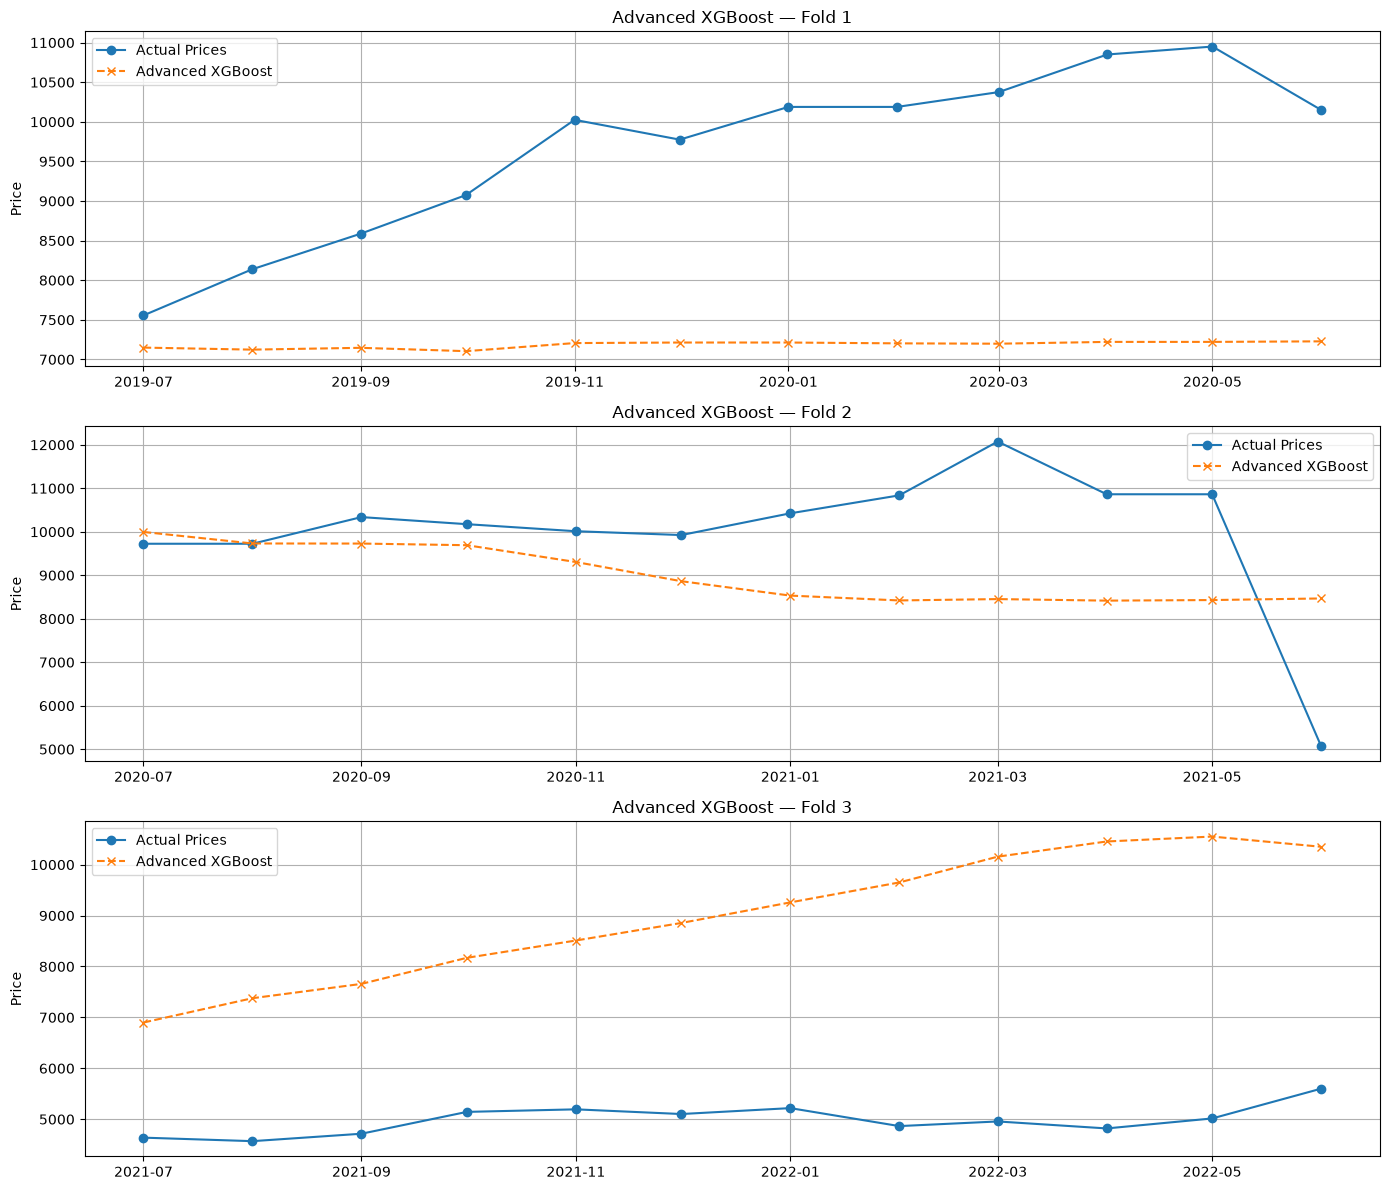

In [45]:
### Plot predictions

fig, axes = plt.subplots(3, 1, figsize=(14, 12))

for i, fold in enumerate([1, 2, 3]):

    origin = fold_origins[fold - 1]
    actual = development_data.iloc[origin:origin+12]

    axes[i].plot(
        actual.index,
        actual.values,
        marker='o',
        label='Actual Prices'
    )

    axes[i].plot(
        advanced_xgb_predictions[fold].index,
        advanced_xgb_predictions[fold].values,
        marker='x',
        linestyle='--',
        label='Advanced XGBoost'
    )

    axes[i].set_title(f'Advanced XGBoost — Fold {fold}')
    axes[i].set_ylabel('Price')
    axes[i].legend()
    axes[i].grid(True)

plt.tight_layout()
plt.show()

,Feature,Importance
0,lag_1,0.278565
14,rolling_max_6,0.276242
7,rolling_mean_3,0.147730
10,rolling_max_3,0.075649
17,rolling_min_12,0.058998
20,momentum_3,0.022321
13,rolling_min_6,0.016316
19,momentum_1,0.013745
11,rolling_mean_6,0.012219
6,lag_12,0.011127


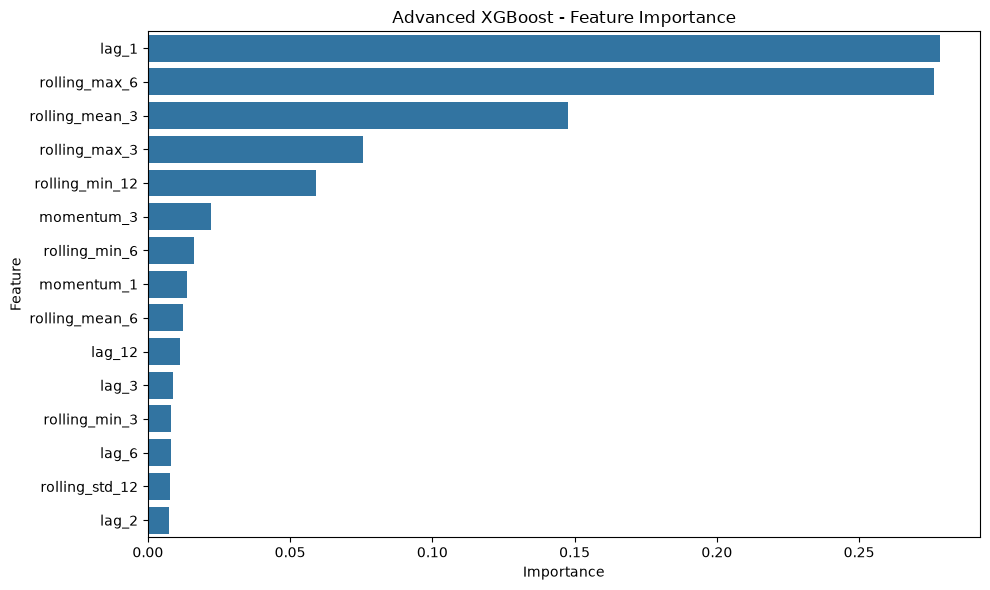

In [47]:
### Advanced model diagnosis

# Feature importance from the latest trained model

importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

display(importance.head(15))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Advanced XGBoost - Feature Importance')
plt.tight_layout()
plt.show()

### Direct Multi-Horizon XGBoost Forecasting.

In [5]:
##  Prepare dataset for direct forecasting

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb

# Reconstruct the original time series
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

ts = df.set_index('date')['avg_monthly_price'].asfreq('MS')

# Verify dataset
print("Dataset shape:", ts.shape)
print("Start date:", ts.index.min())
print("End date:", ts.index.max())
print("Missing values:", ts.isna().sum())

print("\nLatest observations:")
display(ts.tail(12))


Dataset shape: (249,)
Start date: 2005-01-01 00:00:00
End date: 2025-09-01 00:00:00
Missing values: 0

Latest observations:


date
2024-10-01    13738
2024-11-01    13438
2024-12-01    12250
2025-01-01    11313
2025-02-01    11313
2025-03-01    14188
2025-04-01    14263
2025-05-01    14263
2025-06-01    14263
2025-07-01    16000
2025-08-01    15025
2025-09-01    15750
Freq: MS, Name: avg_monthly_price, dtype: int64

In [ ]:

# Create Direct Multi-Horizon Features

def create_direct_features(series, horizon):

    data = []

    for i in range(12, len(series) - horizon):

        history = series.iloc[:i + 1]
        target_date = series.index[i + horizon]

        row = {
            'origin_date': series.index[i],
            'target_date': target_date,
            'current_price': history.iloc[-1],

            # Lag features
            'lag_1': history.iloc[-1],
            'lag_2': history.iloc[-2],
            'lag_3': history.iloc[-3],
            'lag_6': history.iloc[-6],
            'lag_12': history.iloc[-12],

            # Rolling statistics
            'rolling_mean_3': history.iloc[-3:].mean(),
            'rolling_mean_6': history.iloc[-6:].mean(),
            'rolling_mean_12': history.iloc[-12:].mean(),

            'rolling_std_3': history.iloc[-3:].std(),
            'rolling_std_6': history.iloc[-6:].std(),

            'rolling_min_3': history.iloc[-3:].min(),
            'rolling_max_3': history.iloc[-3:].max(),
            'rolling_min_6': history.iloc[-6:].min(),
            'rolling_max_6': history.iloc[-6:].max(),
            'rolling_min_12': history.iloc[-12:].min(),
            'rolling_max_12': history.iloc[-12:].max(),

            # Target month seasonality
            'month_sin': np.sin(2 * np.pi * target_date.month / 12),
            'month_cos': np.cos(2 * np.pi * target_date.month / 12),

            # Forecast horizon
            'horizon': horizon,

            # Target
            'target': series.iloc[i + horizon]
        }

        data.append(row)

    return pd.DataFrame(data)


# Generate datasets for all 12 horizons
direct_datasets = {}

for h in range(1, 13):
    direct_datasets[h] = create_direct_features(ts, h)

print("DIRECT FORECASTING DATASETS")
print("-" * 45)

for h, data in direct_datasets.items():
    print(
        f"Horizon {h:2d} months | "
        f"Shape: {data.shape} | "
        f"First target: {data['target_date'].iloc[0].date()}"
    )

print("\nExample: 3-month horizon")
display(direct_datasets[3].head())


DIRECT FORECASTING DATASETS
---------------------------------------------
Horizon  1 months | Shape: (236, 23) | First target: 2006-02-01
Horizon  2 months | Shape: (235, 23) | First target: 2006-03-01
Horizon  3 months | Shape: (234, 23) | First target: 2006-04-01
Horizon  4 months | Shape: (233, 23) | First target: 2006-05-01
Horizon  5 months | Shape: (232, 23) | First target: 2006-06-01
Horizon  6 months | Shape: (231, 23) | First target: 2006-07-01
Horizon  7 months | Shape: (230, 23) | First target: 2006-08-01
Horizon  8 months | Shape: (229, 23) | First target: 2006-09-01
Horizon  9 months | Shape: (228, 23) | First target: 2006-10-01
Horizon 10 months | Shape: (227, 23) | First target: 2006-11-01
Horizon 11 months | Shape: (226, 23) | First target: 2006-12-01
Horizon 12 months | Shape: (225, 23) | First target: 2007-01-01

Example: 3-month horizon


,origin_date,target_date,current_price,lag_1,lag_2,lag_3,lag_6,lag_12,rolling_mean_3,rolling_mean_6,...,rolling_min_3,rolling_max_3,rolling_min_6,rolling_max_6,rolling_min_12,rolling_max_12,month_sin,month_cos,horizon,target
0,2006-01-01,2006-04-01,4000,4000,3813,4665,5149,5476,4159.333333,4514.666667,...,3813,4665,3813,5149,3813,5876,8.660254e-01,-0.500000,3,3500
1,2006-02-01,2006-05-01,4755,4755,4000,3813,4899,5466,4189.333333,4449.000000,...,3813,4755,3813,4899,3813,5876,5.000000e-01,-0.866025,3,6000
2,2006-03-01,2006-06-01,4176,4176,4755,4000,4562,5487,4310.333333,4328.500000,...,4000,4755,3813,4755,3813,5876,1.224647e-16,-1.000000,3,4964
3,2006-04-01,2006-07-01,3500,3500,4176,4755,4665,5876,4143.666667,4151.500000,...,3500,4755,3500,4755,3500,5876,-5.000000e-01,-0.866025,3,4632
4,2006-05-01,2006-08-01,6000,6000,3500,4176,3813,5058,4558.666667,4374.000000,...,3500,6000,3500,6000,3500,6000,-8.660254e-01,-0.500000,3,4696


In [7]:

#  Prepare rolling-origin validation

# Original validation fold origins
fold_origins = [174, 186, 198]

fold_dates = [ts.index[i] for i in fold_origins]

# Features used for training
feature_cols = [
    col for col in direct_datasets[1].columns
    if col not in ['origin_date', 'target_date', 'target',
                   'current_price', 'horizon']
]

print("FEATURES:", len(feature_cols))
print(feature_cols)

print("\nROLLING VALIDATION FOLDS")
for fold, origin in enumerate(fold_dates, 1):
    print(f"\nFold {fold}")
    print("Forecast origin:", origin.date())
    print("Forecast start:", (origin + pd.DateOffset(months=1)).date())
    print("Forecast end:", (origin + pd.DateOffset(months=12)).date())

# Check training availability for every horizon
print("\nTRAINING SAMPLE AVAILABILITY")

for fold, origin in enumerate(fold_dates, 1):
    print(f"\nFold {fold}")

    for h in range(1, 13):
        data = direct_datasets[h]

        train_data = data[data['target_date'] <= origin]
        validation_data = data[data['origin_date'] == origin]

        print(
            f"Horizon {h:2d}: "
            f"Train={len(train_data):3d}, "
            f"Validation={len(validation_data)}"
        )


FEATURES: 18
['lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'rolling_mean_3', 'rolling_mean_6', 'rolling_mean_12', 'rolling_std_3', 'rolling_std_6', 'rolling_min_3', 'rolling_max_3', 'rolling_min_6', 'rolling_max_6', 'rolling_min_12', 'rolling_max_12', 'month_sin', 'month_cos']

ROLLING VALIDATION FOLDS

Fold 1
Forecast origin: 2019-07-01
Forecast start: 2019-08-01
Forecast end: 2020-07-01

Fold 2
Forecast origin: 2020-07-01
Forecast start: 2020-08-01
Forecast end: 2021-07-01

Fold 3
Forecast origin: 2021-07-01
Forecast start: 2021-08-01
Forecast end: 2022-07-01

TRAINING SAMPLE AVAILABILITY

Fold 1
Horizon  1: Train=162, Validation=1
Horizon  2: Train=161, Validation=1
Horizon  3: Train=160, Validation=1
Horizon  4: Train=159, Validation=1
Horizon  5: Train=158, Validation=1
Horizon  6: Train=157, Validation=1
Horizon  7: Train=156, Validation=1
Horizon  8: Train=155, Validation=1
Horizon  9: Train=154, Validation=1
Horizon 10: Train=153, Validation=1
Horizon 11: Train=152, Validation

In [8]:

# Correct forecast origins: last month of training before each validation window

fold_origins = [173, 185, 197]

fold_dates = [ts.index[i] for i in fold_origins]

print("CORRECTED ROLLING VALIDATION FOLDS")

for fold, origin in enumerate(fold_dates, 1):

    forecast_start = origin + pd.DateOffset(months=1)
    forecast_end = origin + pd.DateOffset(months=12)

    print(f"\nFold {fold}")
    print("Training ends:", origin.date())
    print("Forecast starts:", forecast_start.date())
    print("Forecast ends:", forecast_end.date())

print("\nTRAINING SAMPLE AVAILABILITY")

for fold, origin in enumerate(fold_dates, 1):

    print(f"\nFold {fold}")

    for h in range(1, 13):

        data = direct_datasets[h]

        train_data = data[data['target_date'] <= origin]

        validation_data = data[
            data['origin_date'] == origin
        ]

        assert len(validation_data) == 1

        print(
            f"Horizon {h:2d}: "
            f"Train={len(train_data):3d}, "
            f"Validation={len(validation_data)}"
        )


CORRECTED ROLLING VALIDATION FOLDS

Fold 1
Training ends: 2019-06-01
Forecast starts: 2019-07-01
Forecast ends: 2020-06-01

Fold 2
Training ends: 2020-06-01
Forecast starts: 2020-07-01
Forecast ends: 2021-06-01

Fold 3
Training ends: 2021-06-01
Forecast starts: 2021-07-01
Forecast ends: 2022-06-01

TRAINING SAMPLE AVAILABILITY

Fold 1
Horizon  1: Train=161, Validation=1
Horizon  2: Train=160, Validation=1
Horizon  3: Train=159, Validation=1
Horizon  4: Train=158, Validation=1
Horizon  5: Train=157, Validation=1
Horizon  6: Train=156, Validation=1
Horizon  7: Train=155, Validation=1
Horizon  8: Train=154, Validation=1
Horizon  9: Train=153, Validation=1
Horizon 10: Train=152, Validation=1
Horizon 11: Train=151, Validation=1
Horizon 12: Train=150, Validation=1

Fold 2
Horizon  1: Train=173, Validation=1
Horizon  2: Train=172, Validation=1
Horizon  3: Train=171, Validation=1
Horizon  4: Train=170, Validation=1
Horizon  5: Train=169, Validation=1
Horizon  6: Train=168, Validation=1
Horizon

In [9]:
### Train direct XGBoost models


from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

direct_results = []
direct_predictions = {}

for fold, origin in enumerate(fold_dates, 1):

    print(f"\nTraining Fold {fold}...")

    for h in range(1, 13):

        data = direct_datasets[h]

        # Only use targets available at forecast origin
        train_data = data[
            data['target_date'] <= origin
        ].copy()

        # Select the observation originating at this date
        validation_data = data[
            data['origin_date'] == origin
        ].copy()

        X_train = train_data[feature_cols]
        y_train = train_data['target']

        X_valid = validation_data[feature_cols]

        actual = validation_data['target'].iloc[0]
        target_date = validation_data['target_date'].iloc[0]

        model = XGBRegressor(
            n_estimators=200,
            max_depth=2,
            learning_rate=0.03,
            min_child_weight=3,
            reg_lambda=5,
            objective='reg:squarederror',
            random_state=42,
            n_jobs=-1,
            verbosity=0
        )

        model.fit(X_train, y_train)

        prediction = model.predict(X_valid)[0]

        direct_predictions[(fold, h)] = {
            'date': target_date,
            'actual': actual,
            'predicted': prediction
        }

        direct_results.append({
            'Fold': fold,
            'Horizon': h,
            'Date': target_date,
            'Actual': actual,
            'Predicted': prediction,
            'Absolute_Error': abs(actual - prediction),
            'Squared_Error': (actual - prediction) ** 2
        })

    print(f"Fold {fold} completed.")

direct_results_df = pd.DataFrame(direct_results)

print("\nDirect forecasting completed.")
print("Total predictions:", len(direct_results_df))

display(direct_results_df.round(2))



Training Fold 1...
Fold 1 completed.

Training Fold 2...
Fold 2 completed.

Training Fold 3...
Fold 3 completed.

Direct forecasting completed.
Total predictions: 36


,Fold,Horizon,Date,Actual,Predicted,Absolute_Error,Squared_Error
0,1,1,2019-07-01,7556,7265.359863,290.64,84473.68
1,1,2,2019-08-01,8138,7329.259766,808.74,654059.98
2,1,3,2019-09-01,8588,7482.399902,1105.60,1222353.74
3,1,4,2019-10-01,9075,7292.919922,1782.08,3175816.37
4,1,5,2019-11-01,10025,7225.669922,2799.33,7836268.02
5,1,6,2019-12-01,9775,6859.529785,2915.47,8499972.27
6,1,7,2020-01-01,10188,6801.490234,3386.51,11468445.09
7,1,8,2020-02-01,10188,7038.000000,3150.00,9922487.70
8,1,9,2020-03-01,10375,7201.040039,3173.96,10074000.14
9,1,10,2020-04-01,10850,7278.279785,3571.72,12757157.39


In [10]:
### Calculate evaluation metrics

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

direct_results_df = pd.DataFrame(direct_results)

mae = mean_absolute_error(
    direct_results_df['Actual'],
    direct_results_df['Predicted']
)

rmse = np.sqrt(mean_squared_error(
    direct_results_df['Actual'],
    direct_results_df['Predicted']
))

mape = np.mean(
    np.abs(
        (direct_results_df['Actual'] - direct_results_df['Predicted'])
        / direct_results_df['Actual']
    )
) * 100

print("Direct XGBoost Overall Performance")
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAPE: {mape:.2f}%")


Direct XGBoost Overall Performance
MAE:  2224.72
RMSE: 2433.48
MAPE: 30.08%


In [11]:
### Evaluate performance by horizon
horizon_metrics = direct_results_df.groupby('Horizon').apply(
    lambda group: pd.Series({
        'MAE': mean_absolute_error(
            group['Actual'], group['Predicted']
        ),
        'RMSE': np.sqrt(mean_squared_error(
            group['Actual'], group['Predicted']
        )),
        'MAPE': np.mean(
            np.abs(
                (group['Actual'] - group['Predicted'])
                / group['Actual']
            )
        ) * 100
    }),
    include_groups=False
).reset_index()

display(horizon_metrics.round(2))


,Horizon,MAE,RMSE,MAPE
0,1,951.96,1309.05,18.43
1,2,1067.87,1355.57,20.01
2,3,1409.41,1504.23,22.62
3,4,1600.65,1673.41,23.12
4,5,2087.22,2186.95,27.75
5,6,2236.61,2314.24,30.07
6,7,2590.19,2654.73,31.52
7,8,2739.11,2797.19,33.21
8,9,3222.65,3355.34,36.47
9,10,3220.79,3230.98,41.08


In [12]:
### Compare Direct XGBoost with the Naive baseline

naive_results = []

for fold, origin in enumerate(fold_dates, 1):
    origin_price = ts.loc[origin]

    for h in range(1, 13):
        prediction_info = direct_predictions[(fold, h)]

        naive_results.append({
            'Fold': fold,
            'Horizon': h,
            'Date': prediction_info['date'],
            'Actual': prediction_info['actual'],
            'Predicted': origin_price
        })

naive_results_df = pd.DataFrame(naive_results)

for name, results in [
    ('Naive', naive_results_df),
    ('Direct XGBoost', direct_results_df)
]:
    mae = mean_absolute_error(results['Actual'], results['Predicted'])
    rmse = np.sqrt(mean_squared_error(results['Actual'], results['Predicted']))
    mape = np.mean(
        np.abs((results['Actual'] - results['Predicted']) / results['Actual'])
    ) * 100

    print(f"\n{name}")
    print(f"MAE:  {mae:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"MAPE: {mape:.2f}%")


Naive
MAE:  1101.17
RMSE: 1680.49
MAPE: 12.99%

Direct XGBoost
MAE:  2224.72
RMSE: 2433.48
MAPE: 30.08%



### Direct Multi-Horizon XGBoost — Experiment Conclusion

A direct multi-horizon XGBoost approach was tested using 12 separate models, one for each forecast horizon.

The model achieved:
- MAE: 2,224.72
- RMSE: 2,433.48
- MAPE: 30.08%

The Naive baseline, evaluated on the same 36 forecast dates, achieved:
- MAE: 1,101.17
- RMSE: 1,680.49
- MAPE: 12.99%

Direct XGBoost performed worse than the Naive baseline. Its prediction errors increased at longer forecast horizons.

Therefore, Direct XGBoost was not selected as the final forecasting model. This experiment demonstrates that more complex machine learning models do not necessarily outperform simple statistical baselines on limited time-series datasets.


In [13]:
###Set up the comparison

statistical_results = []

for fold, origin in enumerate(fold_dates, 1):
    train = ts.loc[:origin]

    print(
        f"Fold {fold}: Training ends {train.index[-1].date()}, "
        f"observations: {len(train)}"
    )

Fold 1: Training ends 2019-06-01, observations: 174
Fold 2: Training ends 2020-06-01, observations: 186
Fold 3: Training ends 2021-06-01, observations: 198


In [14]:
## Evaluate Holt-Winters and SARIMA

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

statistical_results = []

for fold, origin in enumerate(fold_dates, 1):

    train = ts.loc[:origin]
    actual = ts.loc[
        origin + pd.offsets.MonthBegin(1):
        origin + pd.DateOffset(months=12)
    ]

    # Holt-Winters: damped additive trend, no seasonality
    hw_model = ExponentialSmoothing(
        train,
        trend='add',
        damped_trend=True,
        seasonal=None
    ).fit(optimized=True)

    hw_forecast = hw_model.forecast(12)

    # SARIMA (0,1,1)(0,1,1,12)
    sarima_model = SARIMAX(
        train,
        order=(0, 1, 1),
        seasonal_order=(0, 1, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(disp=False)

    sarima_forecast = sarima_model.forecast(12)

    for date in actual.index:
        statistical_results.append({
            'Fold': fold,
            'Date': date,
            'Actual': actual.loc[date],
            'HW_Predicted': hw_forecast.loc[date],
            'SARIMA_Predicted': sarima_forecast.loc[date]
        })

statistical_results_df = pd.DataFrame(statistical_results)

print("Statistical model forecasts completed.")
print("Total predictions:", len(statistical_results_df))
display(statistical_results_df.head(12).round(2))

Statistical model forecasts completed.
Total predictions: 36


,Fold,Date,Actual,HW_Predicted,SARIMA_Predicted
0,1,2019-07-01,7556,7494.60,7495.44
1,1,2019-08-01,8138,7501.17,7552.35
2,1,2019-09-01,8588,7507.70,7706.96
3,1,2019-10-01,9075,7514.19,7782.28
4,1,2019-11-01,10025,7520.65,7778.05
5,1,2019-12-01,9775,7527.08,7643.76
6,1,2020-01-01,10188,7533.48,7756.06
7,1,2020-02-01,10188,7539.84,7673.53
8,1,2020-03-01,10375,7546.17,7734.06
9,1,2020-04-01,10850,7552.46,7662.57


In [15]:
### Calculate model performance

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

comparison_results = []

models = {
    'Naive': naive_results_df['Predicted'],
    'Holt-Winters': statistical_results_df['HW_Predicted'],
    'SARIMA': statistical_results_df['SARIMA_Predicted'],
    'Direct XGBoost': direct_results_df['Predicted']
}

actual = statistical_results_df['Actual']

for name, predictions in models.items():

    mae = mean_absolute_error(actual, predictions)

    rmse = np.sqrt(
        mean_squared_error(actual, predictions)
    )

    mape = np.mean(
        np.abs((actual - predictions) / actual)
    ) * 100

    comparison_results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.sort_values('RMSE').round(2)
)

,Model,MAE,RMSE,MAPE
2,SARIMA,1034.80,1604.65,12.58
1,Holt-Winters,1088.06,1658.25,12.86
0,Naive,1101.17,1680.49,12.99
3,Direct XGBoost,2224.72,2433.48,30.08



### Final Model Selection

Four forecasting approaches were compared using three chronological validation windows, with 36 predictions per model.

The SARIMA (0,1,1)(0,1,1,12) model achieved the best results:

- MAE: 1,034.80
- RMSE: 1,604.65
- MAPE: 12.58%

It outperformed Holt-Winters and the Naive baseline. Direct XGBoost performed considerably worse.

Therefore, SARIMA was selected as the final forecasting model.

The results indicate that the statistical approach is more suitable for this dataset than the tested machine learning approaches. However, the model may struggle during sudden market changes, so forecasts should be monitored and updated as new data becomes available.


In [17]:
# Generate 12-month forecast
forecast_result = final_model.get_forecast(steps=12)

# Get forecast summary
forecast_df = forecast_result.summary_frame()

# Keep only the required columns
forecast_df = forecast_df[
    ['mean', 'mean_ci_lower', 'mean_ci_upper']
].copy()

# Rename columns
forecast_df.columns = [
    'Forecast',
    'Lower_CI',
    'Upper_CI'
]

# Add forecast dates
forecast_df.insert(0, 'Date', forecast_df.index)

# Reset index
forecast_df = forecast_df.reset_index(drop=True)

# Round values
forecast_df[['Forecast', 'Lower_CI', 'Upper_CI']] = (
    forecast_df[['Forecast', 'Lower_CI', 'Upper_CI']].round(2)
)

display(forecast_df)

print("Training data ends:", ts.index[-1].date())
print("Forecast starts:", forecast_df['Date'].min().date())
print("Forecast ends:", forecast_df['Date'].max().date())

,Date,Forecast,Lower_CI,Upper_CI
0,2025-10-01,15826.92,14093.52,17560.32
1,2025-11-01,15928.74,13482.33,18375.15
2,2025-12-01,16408.04,13413.85,19402.23
3,2026-01-01,16174.01,12717.81,19630.21
4,2026-02-01,16120.02,12256.69,19983.35
5,2026-03-01,16680.93,12449.64,20912.22
6,2026-04-01,16652.36,12082.64,21222.08
7,2026-05-01,16763.50,11878.74,21648.26
8,2026-06-01,16262.53,11081.86,21443.20
9,2026-07-01,16397.51,10936.94,21858.08


Training data ends: 2025-09-01
Forecast starts: 2025-10-01
Forecast ends: 2026-09-01


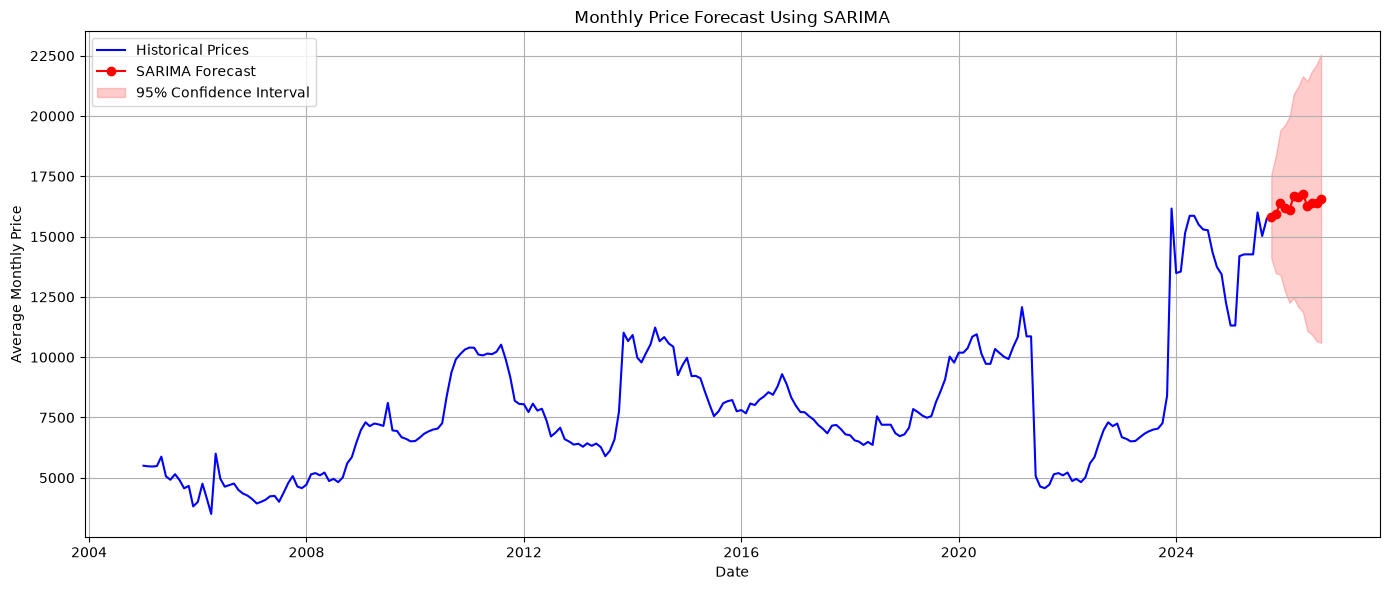

In [18]:
### Visualizing the forecast

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    ts.index,
    ts.values,
    label='Historical Prices',
    color='blue'
)

plt.plot(
    forecast_df['Date'],
    forecast_df['Forecast'],
    label='SARIMA Forecast',
    color='red',
    marker='o'
)

plt.fill_between(
    forecast_df['Date'],
    forecast_df['Lower_CI'],
    forecast_df['Upper_CI'],
    alpha=0.2,
    color='red',
    label='95% Confidence Interval'
)

plt.title('Monthly Price Forecast Using SARIMA')
plt.xlabel('Date')
plt.ylabel('Average Monthly Price')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### Business Interpretation of Forecast

The selected SARIMA model forecasts monthly average prices for October 2025 to September 2026.

The forecast values remain relatively stable, with a gradual increase towards the end of the forecast period.

The 95% confidence intervals become wider over time, indicating greater uncertainty for longer-term predictions.

Business applications:

1. **Inventory planning:** Businesses can use expected price movements to plan purchasing and storage.
2. **Procurement:** Buyers can use forecasts to support purchasing schedules and budget estimates.
3. **Pricing strategy:** Sellers can use forecasts as one input when reviewing pricing decisions.
4. **Risk management:** Confidence intervals can help businesses prepare for possible price fluctuations.
5. **Supply planning:** Agricultural organizations can use forecasts to support production and distribution planning.

Forecasts should be treated as decision-support information rather than guaranteed future prices.


## 12.10 Measuring Business Effectiveness

The effectiveness of the forecasting system can be measured by comparing business performance before and after implementing the forecast.

### Key Performance Indicators (KPIs)

1. **Forecast Accuracy:** Track MAE, RMSE and MAPE against actual monthly prices.
2. **Procurement Cost:** Compare actual purchasing costs with planned procurement costs.
3. **Inventory Efficiency:** Measure reductions in excess inventory and stock shortages.
4. **Budget Accuracy:** Compare forecast-based budgets with actual expenditure.
5. **Decision Improvement:** Measure how often forecast information supports successful purchasing and pricing decisions.

### Evaluation Approach

- Record baseline business performance before using forecasts.
- Apply forecast-based purchasing and inventory decisions.
- Compare results over equivalent periods.
- Calculate cost savings, inventory improvements and forecast accuracy.
- Review performance monthly and update the model when necessary.

The forecasting system should be considered effective when it improves business decisions and reduces avoidable costs without increasing operational risks.


In [19]:
###Measure procurement budget accuracy

import numpy as np
import pandas as pd

# Assumed monthly procurement quantity
monthly_quantity = 100

# Use SARIMA validation predictions
business_df = statistical_results_df[
    ['Date', 'Actual', 'SARIMA_Predicted']
].copy()

# Calculate estimated and actual procurement costs
business_df['Estimated_Cost'] = (
    business_df['SARIMA_Predicted'] * monthly_quantity
)

business_df['Actual_Cost'] = (
    business_df['Actual'] * monthly_quantity
)

# Calculate budget deviation
business_df['Budget_Error'] = (
    business_df['Estimated_Cost'] - business_df['Actual_Cost']
)

business_df['Absolute_Budget_Error'] = (
    business_df['Budget_Error'].abs()
)

display(business_df.head(12).round(2))

print("\nProcurement Budget Evaluation")
print("Average estimated monthly cost:",
      round(business_df['Estimated_Cost'].mean(), 2))

print("Average actual monthly cost:",
      round(business_df['Actual_Cost'].mean(), 2))

print("Average absolute budget error:",
      round(business_df['Absolute_Budget_Error'].mean(), 2))

print("Total absolute budget error:",
      round(business_df['Absolute_Budget_Error'].sum(), 2))

,Date,Actual,SARIMA_Predicted,Estimated_Cost,Actual_Cost,Budget_Error,Absolute_Budget_Error
0,2019-07-01,7556,7495.44,749543.80,755600,-6056.20,6056.20
1,2019-08-01,8138,7552.35,755234.84,813800,-58565.16,58565.16
2,2019-09-01,8588,7706.96,770695.93,858800,-88104.07,88104.07
3,2019-10-01,9075,7782.28,778227.70,907500,-129272.30,129272.30
4,2019-11-01,10025,7778.05,777804.55,1002500,-224695.45,224695.45
5,2019-12-01,9775,7643.76,764375.63,977500,-213124.37,213124.37
6,2020-01-01,10188,7756.06,775605.64,1018800,-243194.36,243194.36
7,2020-02-01,10188,7673.53,767352.93,1018800,-251447.07,251447.07
8,2020-03-01,10375,7734.06,773405.65,1037500,-264094.35,264094.35
9,2020-04-01,10850,7662.57,766257.15,1085000,-318742.85,318742.85



Procurement Budget Evaluation
Average estimated monthly cost: 769446.87
Average actual monthly cost: 821466.67
Average absolute budget error: 103480.41
Total absolute budget error: 3725294.59


In [20]:
### Calculate budget error percentage

# Calculate percentage budget error
average_actual_cost = business_df['Actual_Cost'].mean()

average_budget_error = (
    business_df['Absolute_Budget_Error'].mean()
)

budget_error_percentage = (
    average_budget_error / average_actual_cost
) * 100

print(f"Average Budget Error: {budget_error_percentage:.2f}%")

# Calculate forecast bias
forecast_bias = (
    business_df['Budget_Error'].mean()
)

print(f"Forecast Bias: {forecast_bias:.2f}")

if forecast_bias < 0:
    print("The model tends to underestimate procurement costs.")
elif forecast_bias > 0:
    print("The model tends to overestimate procurement costs.")
else:
    print("The model has no average forecast bias.")

Average Budget Error: 12.60%
Forecast Bias: -52019.80
The model tends to underestimate procurement costs.



### Business Effectiveness Evaluation

The SARIMA model was evaluated using a simulated procurement scenario with a monthly quantity of 100 units.

The evaluation produced the following results:

- Average budget error: 12.60%
- Average forecast bias: -52,019.80
- Forecast tendency: Underestimation of procurement costs.

The negative forecast bias indicates that predicted procurement costs were generally lower than actual costs during the evaluation period.

Business implications:

1. Procurement teams should maintain a contingency budget.
2. Forecasts should be reviewed before major purchasing decisions.
3. Actual prices should be compared with predicted prices every month.
4. Model performance should be monitored during sudden market changes.

This evaluation demonstrates how forecasting accuracy can support procurement planning. Actual financial savings must be measured through a real-world implementation.


In [6]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import pandas as pd
import numpy as np

fold_dates = [
    ts.index[173],
    ts.index[185],
    ts.index[197]
]

statistical_results = []

for fold, origin in enumerate(fold_dates, 1):

    train = ts.loc[:origin]

    actual = ts.loc[
        origin + pd.offsets.MonthBegin(1):
        origin + pd.DateOffset(months=12)
    ]

    model = SARIMAX(
        train,
        order=(0, 1, 1),
        seasonal_order=(0, 1, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(disp=False)

    predictions = model.forecast(steps=12)

    for date in actual.index:
        statistical_results.append({
            'Fold': fold,
            'Date': date,
            'Actual': actual.loc[date],
            'SARIMA_Predicted': predictions.loc[date]
        })

statistical_results_df = pd.DataFrame(statistical_results)

print("Validation dataset restored.")
print("Total observations:", len(statistical_results_df))

display(statistical_results_df.head())

Validation dataset restored.
Total observations: 36


,Fold,Date,Actual,SARIMA_Predicted
0,1,2019-07-01,7556,7495.438036
1,1,2019-08-01,8138,7552.348424
2,1,2019-09-01,8588,7706.959314
3,1,2019-10-01,9075,7782.277004
4,1,2019-11-01,10025,7778.045533


In [7]:
###Monitor forecast errors

import numpy as np
import pandas as pd

# Prepare monitoring dataset
monitoring_df = statistical_results_df[
    ['Date', 'Actual', 'SARIMA_Predicted']
].copy()

# Calculate forecast errors
monitoring_df['Error'] = (
    monitoring_df['Actual'] - monitoring_df['SARIMA_Predicted']
)

monitoring_df['Absolute_Error'] = (
    monitoring_df['Error'].abs()
)

monitoring_df['Percentage_Error'] = (
    monitoring_df['Absolute_Error']
    / monitoring_df['Actual']
) * 100

# Define alert threshold
error_threshold = 15

monitoring_df['Status'] = np.where(
    monitoring_df['Percentage_Error'] > error_threshold,
    'ALERT',
    'NORMAL'
)

display(monitoring_df.head(15).round(2))

# Monitoring summary
print("\nProduction Monitoring Summary")
print("Total observations:", len(monitoring_df))
print("Normal observations:",
      (monitoring_df['Status'] == 'NORMAL').sum())
print("Alert observations:",
      (monitoring_df['Status'] == 'ALERT').sum())

,Date,Actual,SARIMA_Predicted,Error,Absolute_Error,Percentage_Error,Status
0,2019-07-01,7556,7495.44,60.56,60.56,0.80,NORMAL
1,2019-08-01,8138,7552.35,585.65,585.65,7.20,NORMAL
2,2019-09-01,8588,7706.96,881.04,881.04,10.26,NORMAL
3,2019-10-01,9075,7782.28,1292.72,1292.72,14.24,NORMAL
4,2019-11-01,10025,7778.05,2246.95,2246.95,22.41,ALERT
5,2019-12-01,9775,7643.76,2131.24,2131.24,21.80,ALERT
6,2020-01-01,10188,7756.06,2431.94,2431.94,23.87,ALERT
7,2020-02-01,10188,7673.53,2514.47,2514.47,24.68,ALERT
8,2020-03-01,10375,7734.06,2640.94,2640.94,25.45,ALERT
9,2020-04-01,10850,7662.57,3187.43,3187.43,29.38,ALERT



Production Monitoring Summary
Total observations: 36
Normal observations: 26
Alert observations: 10



### Production Monitoring Results

The SARIMA forecasting model was evaluated using 36 validation observations with a 15% percentage-error alert threshold.

Monitoring results:

- Total observations: 36
- Normal observations: 26
- Alert observations: 10
- Normal rate: 72.22%
- Alert rate: 27.78%

The monitoring system identified periods where forecast errors exceeded the defined threshold.

In particular, the November 2019 to June 2020 period showed consistent underestimation of actual prices.

These alerts indicate that the forecasting model may require investigation or retraining when market conditions change significantly.


In [8]:
# Calculate average absolute percentage error by fold

drift_summary = monitoring_df.groupby('Date').agg(
    Mean_Error=('Percentage_Error', 'mean')
).reset_index()

drift_summary['Rolling_Error'] = (
    drift_summary['Mean_Error'].rolling(window=3).mean()
)

display(drift_summary.tail(15).round(2))

,Date,Mean_Error,Rolling_Error
21,2021-04-01,3.62,6.72
22,2021-05-01,1.68,6.09
23,2021-06-01,105.99,37.10
24,2021-07-01,1.39,36.36
25,2021-08-01,1.85,36.41
26,2021-09-01,4.53,2.59
27,2021-10-01,2.04,2.81
28,2021-11-01,1.67,2.75
29,2021-12-01,3.11,2.27
30,2022-01-01,1.66,2.15


In [ ]:
# Define rolling error threshold
drift_threshold = 15

drift_summary['Drift_Status'] = np.where(
    drift_summary['Rolling_Error'] > drift_threshold,
    'DRIFT ALERT',
    'NORMAL'
)

display(drift_summary.tail(15).round(2))

print("\nDrift Monitoring Summary")
print(
    "Drift alerts:",
    (drift_summary['Drift_Status'] == 'DRIFT ALERT').sum()
)

print(
    "Normal periods:",
    (drift_summary['Drift_Status'] == 'NORMAL').sum()
)


,Date,Mean_Error,Rolling_Error,Drift_Status
21,2021-04-01,3.62,6.72,NORMAL
22,2021-05-01,1.68,6.09,NORMAL
23,2021-06-01,105.99,37.10,DRIFT ALERT
24,2021-07-01,1.39,36.36,DRIFT ALERT
25,2021-08-01,1.85,36.41,DRIFT ALERT
26,2021-09-01,4.53,2.59,NORMAL
27,2021-10-01,2.04,2.81,NORMAL
28,2021-11-01,1.67,2.75,NORMAL
29,2021-12-01,3.11,2.27,NORMAL
30,2022-01-01,1.66,2.15,NORMAL



Drift Monitoring Summary
Drift alerts: 12
Normal periods: 24


### Model Drift Detection

A rolling error-based monitoring mechanism was implemented to identify potential deterioration in forecasting performance.

The system uses a three-month rolling average of percentage forecasting errors and a threshold of 15%.

Results:
- Total monitoring periods: 36
- Drift alerts: 12
- Normal periods: 24
- Drift alert rate: 33.33%

The system identifies periods where forecast errors remain elevated.

When an alert occurs, the following actions are recommended:

1. Investigate unusual market price movements.
2. Compare recent actual prices with historical patterns.
3. Review model accuracy and input data quality.
4. Retrain the model when sufficient new observations are available.
5. Validate the updated model before deployment.

This mechanism provides an early warning system for potential model performance deterioration.
